# Start

## libraries

In [53]:
import numpy as np
import pandas as pd
import re
from typing import Dict, List, Mapping, Optional

# plots
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations

## plots

In [54]:
# --- Unified Font & Text Settings ---
plt.rcParams["font.family"]    = "monospace"
plt.rcParams["font.monospace"] = ["Lucida Console", "DejaVu Sans Mono"]

fontsize_title = 16
fontsize_label = 14
fontsize_ticks = 12
fontsize_legend = 11

## thermodynamic data

In [55]:
# --- Input Data ---
species_involved = ["Al2O3", "Al2SiO5", "Al2Si2O5(OH)4", "H2O", "SiO2", "Al", "Si", "O2", "H2"]  # List of all species involved in the reactions
resource = "Al2O3"  # Resource species (j) in this case, corundum
reference_elements_i = ["Al", "O2", "Si", "H2"]  # Reference elements (i) for the reactions, chosen based on the species involved and their standard states

# Standard state for elements
standard_state_equivalencies = {
    "O": "O2",
    "Al": "Al",
    "Si": "Si",
    "H": "H2",
    }  # Map atomic to molecular for standard states

# reaction of formation from the reference chemical elements (i) to the resource (j)
reaction_formation_jfromis_sc = { # "sc" stands for "stoichiometric coefficients"
    "Al2O3": 1,
    "Al": -2,
    "O2": -1.5,
}

# Environment conditions
Tenv = 298.15  # K
penv = 1.015 * 10**5  # Pa, not needed for G° calculations but included for completeness

# --- the reference environmental species can change => different dictionaries...
# SZARGUT :
# For Szargut, the values are taken from 🪢 https://www.researchgate.net/profile/Alicia-Valero/publication/271828138_main/data/54d2565d0cf28e069723e580/main.pdf (free access).
# The original paper, where Szargut explains how chemical exergi is computed is 📖 https://doi.org/10.1016/0306-2619(89)90016-0, but I don't have access to it.

# Al2O3 + SiO2 = Al2SiO5
reference_environment_species_k_szargut = ["Al2SiO5", "SiO2"]  # Reference environmental species for Szargut

reaction_formation_jfromks_sc_szargut = { # "sc" stands for "stoichiometric coefficients"
    "Al2O3": 1,
    "Al2SiO5": -1,
    "SiO2": 1,
}

# SiO2 is an env species used,  and Al2SiO5 is an env species created
szargut_chem_exergy_i = { # kj/mol
    "Al": 790.34,   # Aluminium (i)
    "O2": 3.97,  # Dioxygen (i)
    "Si": 854.17,   # Silicon (i)
    "H2": 236.10,  # Dihydrogen (i)
}

HSC_chem_exergy_i = { # kj/mol
    "Al": 795.70,   # Aluminium (i)
    "O2": 3.92,  # Dioxygen (i)
    "Si": 855.00,   # Silicon (i)
    "H2": 236.12,  # Dihydrogen (i)
}

staneck_chem_exergy_i = { # kj/mol # 📖 https://www.sudoc.fr/224722972,  ISBN : 978-3-319-48648-2 = szargut_chem_exergy_i
    "Al": 790.34,   # Aluminium (i)
    "O2": 3.97,  # Dioxygen (i)
    "Si": 854.17,   # Silicon (i)
    "H2": 236.1,  # Dihydrogen (i)
}

rivero_chem_exergy_i = { # kj/mol  # 📖 https://www-sciencedirect-com.docelec.u-bordeaux.fr/science/article/pii/S0360544206000569?via%3Dihub
    "Al": 795.7,   # Aluminium (i)
    "O2": 3.92,  # Dioxygen (i)
    "Si": 855.00,   # Silicon (i)
    "H2": 236.12,  # Dihydrogen (i)
}

szargut_chem_exergy_k = {
    "O2": 3.97,  # Dioxygen (k)
    "Al2SiO5": 3.79,
    "SiO2": 1.44,
    "H2O": 9.49,
}

HSC_chem_exergy_k = {
    "O2": 3.92, # Dioxygen (k)
    "Al2SiO5": 34.55,
    "SiO2": 2.63,
    "H2O": 0.94,
    "Al2Si2O5(OH)4": -10.53 # 29.86, # Halloysite (k4)
    # "Al2Si2O5(OH)4": -10.53, # Kaolinite (k1)
}

staneck_chem_exergy_k = { # = szargut_chem_exergy_k
    "O2": 3.97,  # 
    "Al2SiO5": 3.79,
    "SiO2": 1.44,
    "H2O": 9.49
}

rivero_chem_exergy_k = { # = szargut_chem_exergy_k
    "O2": 3.92,  # 
    "Al2SiO5": 15.32,
    "SiO2": 2.23,
    "H2O": 9.49
}

# Standard Gibbs free energy of formation (ΔGºf) in kJ/mol
DeltafrG_std_szargut_brgm = {
    "Al2O3": -1582.257,  # Corundum (j) 🪢 https://thermoddem.brgm.fr/species/corundumalpha
    "Al2SiO5": -2440.990,  # Aluminite (k1) 
    "SiO2": -856.700,     # Quartz (k2)
    "H2O": -228.59,
}

DeltafrG_std_staneck_brgm = {
    "Al2O3": -1582.257,  # Corundum (j) 🪢 https://thermoddem.brgm.fr/species/corundumalpha
    "Al2SiO5": -2440.990,  # Aluminite (k1) 
    "SiO2": -856.700,     # Quartz (k2)
    "H2O": -228.59,
}

DeltafrG_std_rivero_brgm = {
    "Al2O3": -1582.257,  # Corundum (j) 🪢 https://thermoddem.brgm.fr/species/corundumalpha
    "Al2SiO5": -2440.99,  # Aluminite (k1) 
    "SiO2": -856.700,     # Quartz (k2)
    "H2O": -228.59,
}

DeltafrG_std_HSC = {
    "Al2O3": -1582.274,  # Corundum (j) 
    "Al2SiO5": -2421.647,  # Sillimanite # CAS: 12141-46-7 
    "SiO2": -856.285,     # Quartz (k2)
    "H2O": -237.141,      # Water (k3)
    "Al2Si2O5(OH)4": -3801.813,  # Kaolinite (k4)
}

DeltafrG_std_FS = {
    "Al2O3": -1582.2937,  # corundum (alpha) (j), FactPS
    "Al2SiO5": -3023.6378,  # Al2SiO5_kyanite(s3), FactPS
    "SiO2": -856.3181,     # Quartz(l) (k2), FactPS
    "H2O": -237.1900,      # Water (k3), FactPS
    "Al2Si2O5(OH)4": -3799.6558,  # Kaolinite (k4), FactPS
}

# 📖 DE MEESTER : doi/10.1021/es060167d
# Al2O3 + 2*SiO2 + 2H2O = Al2Si2O5(OH)4
# 2*SiO2 and 2*H2O are env species used, and Al2Si2O5(OH)4 is an env species created
reference_environment_species_k_demeester = ["Al2Si2O5(OH)4", "SiO2", "H2O"]

reaction_formation_jfromks_sc_demeester = { # "sc" stands for "stoichiometric coefficients"
    "Al2O3": 1,
    "Al2Si2O5(OH)4": -1,
    "SiO2": 2,
    "H2O": 2,
}

demeester_chem_exergy_i = { # kj/mol
    "Al" : 1709.2975, # ⚠️ CORRECTED ⚠️ The real value reported is: 809.4 in https://pubs.acs.org/doi/suppl/10.1021/es060167d/suppl_file/es060167dsi20060522_074651.pdf
    "O2": 3.97, # checked ☑️
    "Si" : 853.8, # checked ☑️
    "H2": 236.0, # checked ☑️
}

demeester_chem_exergy_k = { # kj/mol
    "Al2Si2O5(OH)4": 12.26, # assume true
    "SiO2": 1.37, # assume true
    "H2O": 9.49, # assume true
    "O2": 3.97, # 
}

# Standard Gibbs free energy of formation (ΔGºf) in kJ/mol
DeltafrG_std_demeester_brgm = {
    "Al2O3": -1582.257,  # Corundum (j) 🪢 https://thermoddem.brgm.fr/species/corundumalpha
    "Al2Si2O5(OH)4": -5603.8,  # Kaolinite (k1)  
    "SiO2": -856.4,     # Quartz (k2)
    "H2O": -228.5,    # Water (k3)
}


# Standard entropy (S°) in J/mol·K found in thermoddem database 🪢 https://thermoddem.brgm.fr/data 
S_std_brgm = {
    "Al": 28.30,   # Aluminium (i)
    "O2": 205.15,  # Dioxygen (i)
    "Si": 18.81,   # Silicon (i)
    "H2": 130.68,  # Dihydrogen (i)
}

S_std_HSC = {
    "Al": 28.275,   # Aluminium (i)
    "O2": 205.149,  # Dioxygen (i)
    "Si": 18.820,   # Silicon (i)
    "H2": 130.679,  # Dihydrogen (i)
}

S_std_FS = {
    "Al": 28.275,   # Aluminium (i)
    "O2": 205.0376,  # Dioxygen (i) 
    "Si": 18.82,   # Silicon (i)
    "H2": 130.5706,  # Dihydrogen (i)
}           

# Standard enthalpy (H°) in kJ/mol (empty if not provided)
H_std = {}

# Standard Gibbs free energy (G°) in kJ/mol (empty if not provided)
G_std = {}

## ⚠️ Issue potential with Demeester G reported

In [56]:
g_demeester = -5603.8 # kJ/mol
chem_ex_si_dm = 853.8 # kJ/mol
chem_ex_o2_dm = 3.97 # kJ/mol
chem_ex_H2_dm = 236 # kJ/mol
b_ch_kao = 12.26 # kJ/mol
element = "Al2Si2O5(OH)4"
formula_chem_al = (b_ch_kao - (g_demeester + 2*chem_ex_si_dm + 4.5*chem_ex_o2_dm + 2*chem_ex_H2_dm))/2
print(f"The b value we get when we take the g value from holland reported by demeester:\n {formula_chem_al}")
chem_ex_al_reported = 809.4 # kJ/mol
correct_g_compar_to_ex_al = (2*chem_ex_al_reported - b_ch_kao)*-1 - (2*chem_ex_si_dm + 4.5*chem_ex_o2_dm + 2*chem_ex_H2_dm)
print(f"the G value reported from Holland db is: \n {g_demeester}\n while it should be according to Ex value reported by Demeester:\n {correct_g_compar_to_ex_al}")

The b value we get when we take the g value from holland reported by demeester:
 1709.2975000000004
the G value reported from Holland db is: 
 -5603.8
 while it should be according to Ex value reported by Demeester:
 -3804.005


In [57]:
# Standard Gibbs free energy of formation (ΔGºf) in kJ/mol
DeltafrG_std_demeester_brgm = {
    "Al2O3": -1582.257,  # Corundum (j) 🪢 https://thermoddem.brgm.fr/species/corundumalpha
    "Al2Si2O5(OH)4": correct_g_compar_to_ex_al,  # Kaolinite (k1)  
    "SiO2": -856.4,     # Quartz (k2)
    "H2O": -228.5,    # Water (k3)
}

# Functions 
To Compute the Gs values from the inputs

In [58]:
import re
formula = "H2O"
elements = re.findall(r"([A-Z][a-z]*)(\d*)", formula)
print(elements)  # [('H', '2'), ('O', '')]

[('H', '2'), ('O', '')]


## Derive the (Standard Reference Species) SRS Chemical Exergy (B_ch)
✖️ Non-available standard (°) reference species (i) exergies (B_i^°) data

In [59]:
### we at least must used the b_chk of the reference environment species:

# --- Helper Function: Parse Chemical Formula ---
def parse_formula(formula: str, standard_state_equivalencies: Dict[str, str]) -> Dict[str, float]:
    """
    Parse a chemical formula into a dictionary of standard state species and counts.
    """
    # Handle (OH)4
    formula = formula.replace("(OH)4", "O4 H4")
    formula = formula.replace("(", "").replace(")", "")
    elements = re.findall(r"([A-Z][a-z]*)(\d*)", formula)
    counts = {}
    for (element, count) in elements:
        if count == "":
            count = 1
        else:
            count = int(count)
        counts[element] = counts.get(element, 0) + count
    
    # Adjust for standard states
    new_counts = {}
    for element, count in counts.items():
        if element in standard_state_equivalencies:
            std = standard_state_equivalencies[element]
            if std == "O2" and element == "O":
                new_counts[std] = new_counts.get(std, 0) + count / 2.0
            elif std == "H2" and element == "H":
                new_counts[std] = new_counts.get(std, 0) + count / 2.0
            else:
                new_counts[std] = new_counts.get(std, 0) + count
        else:
            new_counts[element] = new_counts.get(element, 0) + count
    return new_counts

def compute_b_chi_sequential(
    chem_exergy_k,
    DeltafrG_std,
    standard_state_equivalencies,
    b_chk_init,
    env_species_order
):
    """
    Strict thermodynamic back-calculation:

    b_chk = ΔGf + Σ(n_i * b_chi_i)

    RULES:
    - ONLY O2 is known initially
    - Si, H are solved (not given)
    - Al is solved last via aluminosilicates
    """

    # ------------------------------------------------------------
    # INITIAL STATE: ONLY O2 IS KNOWN
    # ------------------------------------------------------------
    b_chi = {
        "O2": b_chk_init["O2"]
    }

    def parse(species):
        return parse_formula(species, standard_state_equivalencies)

    def solve(species):
        if species not in chem_exergy_k or species not in DeltafrG_std:
            return False

        stoich = parse(species)

        known_sum = 0.0
        unknown = None

        for el, coef in stoich.items():
            if el in b_chi:
                known_sum += coef * b_chi[el]
            else:
                if unknown is None:
                    unknown = (el, coef)
                else:
                    return False  # too many unknowns

        if unknown is None:
            return False

        el, coef = unknown

        b_chi[el] = (
            chem_exergy_k[species]
            - DeltafrG_std[species]
            - known_sum
        ) / coef

        return True

    # ------------------------------------------------------------
    # STEP 1 — O2 already known
    # ------------------------------------------------------------

    # ------------------------------------------------------------
    # STEP 2 — derive Si and H FIRST (must be causal)
    # ------------------------------------------------------------
    primary_species = ["SiO2", "H2O"]

    for sp in primary_species:
        solve(sp)

    # ------------------------------------------------------------
    # STEP 3 — iterate full propagation for Al system
    # ------------------------------------------------------------
    for _ in range(5):
        for sp in env_species_order:
            solve(sp)

    return b_chi



## Compute the 6Gs
☑️ From vailable standard (°) reference species (i) exergies (B_i^°) data

In [60]:
# --- Function: Compute G° for Elements and Compounds ---
def compute_G_std(
    species: str,
    DeltafrG_std: Dict[str, float],
    S_std: Dict[str, float],
    H_std: Dict[str, float],
    G_std: Dict[str, float],
    reference_elements: List[str],
    standard_state_equivalencies: Dict[str, str],
    Tenv: float
) -> Optional[float]:
    """
    Compute G° (kJ/mol) for a species at given temperature.
    """
    if species in G_std:
        return G_std[species]
    
    # Check if species is an element (in standard state)
    if species in reference_elements:
        if species in S_std:
            return -Tenv * S_std[species] / 1000  # Convert J to kJ
        else:
            return None
    
    # For compounds, use ΔG°f + sum of elements' G°
    if species in DeltafrG_std:
        elements = parse_formula(species, standard_state_equivalencies)
        G_elements = 0
        for element, count in elements.items():
            G_element = compute_G_std(
                element, DeltafrG_std, S_std, H_std, G_std, 
                reference_elements, standard_state_equivalencies, Tenv
            )
            if G_element is None:
                return None
            G_elements += count * G_element
        return DeltafrG_std[species] + G_elements
    
    # Try from H° and S° if available
    if species in S_std and species in H_std:
        return H_std[species] - Tenv * S_std[species] / 1000
    
    return None

# --- Function: Compute G for Reference State sum_i (elements) ---
def compute_std_G_sumi_in_j(
    reaction_formation: Dict[str, float],
    S_std: Dict[str, float],
    Tenv: float
) -> float:
    """
    Compute G(∑i, °) = Σ (stoich_coef * G°_element)
    """
    G_sum_i = 0.0
    for species, coef in reaction_formation.items():
        if coef < 0:  # Reactants (elements)
            if species in S_std:
                G_element = -Tenv * S_std[species] / 1000
                G_sum_i += abs(coef) * G_element
            else:
                raise ValueError(f"Missing S° for element {species}")
    return G_sum_i

# --- Function: Compute G for Reference State sum_k (environmental species) ---
def compute_std_G_sumk_in_j(
    DeltafrG_std: Dict[str, float],
    S_std: Dict[str, float],
    H_std: Dict[str, float],
    G_std: Dict[str, float],
    reference_elements: List[str],
    standard_state_equivalencies: Dict[str, str],
    Tenv: float,
    reaction_formation_j_from_k: Dict[str, float],
    resource: str
) -> float:
    """
    Compute G(∑k, °) = Σ (-coef_k * G°_k_species) from the reaction j = Σ coef_k * k
    """
    G_sum_k = 0.0
    for species, coef in reaction_formation_j_from_k.items():
        if species == resource:
            continue
        G_species = compute_G_std(
            species, DeltafrG_std, S_std, H_std, G_std,
            reference_elements, standard_state_equivalencies, Tenv
        )
        if G_species is None:
            raise ValueError(f"Cannot compute G° for {species}")
        G_sum_k += -coef * G_species
    return G_sum_k

# --- Function: Compute the value of chemical exergy of the sum of environment reference species k present in the resource j
def compute_sumk_in_j(
    chem_exergy_k: Dict[str, float],
    reaction_formation_jfrom_k: Dict[str, float]
) -> float:
    """
    Compute Szargut(∑k, env) from chemical exergies of environmental species
    Based on reaction: j = Al2O3 = Al2SiO5 - SiO2 for Szargut reference environment species
        or j = Al2O3 = Al2Si2O5(OH)4 - 2*SiO2 - 2*H2O for De Meester reference environment species
    """
    # For reaction: Al2O3 -> Al2SiO5 - SiO2
    # B_sumk_in_j = Σ (coef_k * exergy_k) with signs opposite to formation
    if reaction_formation_jfrom_k == reaction_formation_jfromks_sc_szargut:
        szargut_value = 0.0
        for species, coef in reaction_formation_jfrom_k.items():
            if species in chem_exergy_k:
                if species == "Al2O3":
                    continue  # Skip the resource species
                szargut_value += -coef * chem_exergy_k[species]
        return szargut_value
    if reaction_formation_jfrom_k == reaction_formation_jfromks_sc_demeester:
        demeester_value = 0.0
        for species, coef in reaction_formation_jfrom_k.items():
            if species in chem_exergy_k:
                if species == "Al2O3":
                    continue  # Skip the resource species
                demeester_value += -coef * chem_exergy_k[species]
        return demeester_value

# --- Function: Compute the value of chemical exergy of the sum of standard reference species i present in the resource j
def compute_sumi_in_j(
    chem_exergy_i: Dict[str, float],
    reaction_formation_jfrom_i: Dict[str, float]
) -> float:
    """
    Compute Szargut(∑\nν_i * B_ch,i) from chemical exergies of reference elements
    Based on reaction: j = Al2O3 = 2Al + 1.5O2
    """
    # For reaction: Al2O3 -> 2Al + 1.5O2
    # B_sumi_in_j = Σ (coef_i * exergy_i) with signs opposite to formation
    szargut_value = 0.0
    for species, coef in reaction_formation_jfrom_i.items():
        if species in chem_exergy_i:
            if species == "Al2O3":
                continue  # Skip the resource species
            szargut_value += -coef * chem_exergy_i[species]
    return szargut_value

# --- Main Function: Compute All 6 G Values ---
def compute_all_G_values(
    # Thermodynamic data
    DeltafrG_std: Dict[str, float],
    S_std: Dict[str, float],
    H_std: Dict[str, float],
    G_std: Dict[str, float],
    
    # Chemical systems
    resource: str,
    reference_elements_i: List[str],
    reference_species_k: List[str],
    
    # Reactions
    reaction_formation_j_from_i: Mapping[str, float],
    reaction_formation_j_from_k: Mapping[str, float],
    
    # Szargut data
    chem_exergy_k: Dict[str, float],
    chem_exergy_i: Dict[str, float],  # Chemical exergies of elements for Szargut(∑ν_i * B_ch,i)
    
    # Environment
    Tenv: float,
    
    # Helpers
    standard_state_equivalencies: Dict[str, str]
) -> Dict[str, float]:
    """
    Compute all 6 G values and related quantities.
    Returns dictionary with all computed values.
    """
    
    results = {}
    
    # Step 1: Compute G(∑i, °)
    results["G_std_sumi_in_j"] = compute_std_G_sumi_in_j(
        reaction_formation_j_from_i, S_std, Tenv
    )
    
    # Step 2: Compute G(j, °) for resource
    G_std_resource = compute_G_std(
        resource, DeltafrG_std, S_std, H_std, G_std,
        reference_elements_i, standard_state_equivalencies, Tenv
    )
    if G_std_resource is None:
        raise ValueError(f"Cannot compute G° for {resource}")
    results["G_std_j"] = G_std_resource
    
    # Step 3: Compute G(∑k, °)
    results["G_std_sumk_in_j"] = compute_std_G_sumk_in_j(
        DeltafrG_std, S_std, H_std, G_std,
        reference_elements_i, standard_state_equivalencies, Tenv,
        reaction_formation_j_from_k, resource
    )
    
    # Step 4: Compute Szargut exergies for ∑k and ∑i
    results["B_sumk_in_j"] = compute_sumk_in_j(
        chem_exergy_k, reaction_formation_j_from_k
    )
    results["B_sumi_in_j"] = compute_sumi_in_j(
        chem_exergy_i, reaction_formation_j_from_i
    )

    
    # Step 5: Compute G(∑k, env) from relation:
    # G(∑k, °) - G(∑k, env) = B_sumk_in_j(∑ν_k * B_ch,k)
    results["G_env_sumk_in_j"] = results["G_std_sumk_in_j"] - results["B_sumk_in_j"]
    
    # Step 6.1: Compute ΔG° for reaction j ← k
    DeltaG_std_jk = results["G_std_j"] - results["G_std_sumk_in_j"]
    # Step 6.2: Compute ΔG° for reaction j ← i
    DeltaG_std_ji = results["G_std_j"] - results["G_std_sumi_in_j"]
    # Step 6.3: Compute ΔG° for reaction k ← i
    DeltaG_std_ki = results["G_std_sumk_in_j"] - results["G_std_sumi_in_j"]
    
    # Step 7: Compute G(j, env) assuming ΔG^env = ΔG° (only thermomechanical contributions in chemical exergy)
    results["G_env_j"] = DeltaG_std_jk + results["G_env_sumk_in_j"]
    
    # Step 8: Compute G(∑i, env) from B_sumi_in_j(∑ν_i * B_ch,i)
    # DeltaG_std_ji = G(j, °) - G(∑i, °) = G(j, env) - G(∑i, env) => G(∑i, env) = G(j, env) - DeltaG_std_ji
    results["G_env_sumi_in_j"] = results["G_env_j"] - DeltaG_std_ji # can be determined from other ways:
    # results["G_env_sumi_in_j"] = results["G_env_sumk_in_j"] - DeltaG_std_ki # for instance
    
    # Step 9: Compute derived quantities for verification
    results["B_j"] = results["G_std_j"] - results["G_env_sumk_in_j"] # based on Edward and Simpson definition of chemical exergy 📖 https://doi.org/10.1016/j.energy.2011.01.025
    results["DeltaG_std_jk"] = DeltaG_std_jk
    results["DeltaG_env_jk"] = results["G_env_j"] - results["G_env_sumk_in_j"]
    results["DeltaG_std_ji"] = results["G_std_j"] - results["G_std_sumi_in_j"]
    results["DeltaG_env_ji"] = results["G_env_j"] - results["G_env_sumi_in_j"]
    
    return results

# --- Function: Create Results DataFrame ---
def create_results_dataframe(results_dict: Dict[str, float]) -> pd.DataFrame:
    """
    Create a formatted DataFrame from results dictionary.
    """
    # Define the 6 main G values
    main_G_values = {
        "G(∑k, env)": results_dict["G_env_sumk_in_j"],
        "G(j, env)": results_dict["G_env_j"],
        "G(∑k, °)": results_dict["G_std_sumk_in_j"],
        "G(j, °)": results_dict["G_std_j"],
        "G(∑i, env)": results_dict["G_env_sumi_in_j"],
        "G(∑i, °)": results_dict["G_std_sumi_in_j"]
    }
    
    # Create DataFrame for main results
    df_main = pd.DataFrame([
        {"Parameter": k, "Value (kJ/mol)": v, "Type": "Main G Value"}
        for k, v in main_G_values.items()
    ])
    
    # Create DataFrame for derived quantities
    derived_quantities = {
        "B_sumk_in_j(∑ν_k * B_ch,k)": results_dict["B_sumk_in_j"],
        "B_sumi_in_j(∑ν_i * B_ch,i)": results_dict["B_sumi_in_j"],
        "B_j (Chemical Exergy of the resource)": results_dict["B_j"],
        "ΔG°(j ← k)": results_dict["DeltaG_std_jk"],
        "ΔG^env(j ← k)": results_dict["DeltaG_env_jk"],
        "ΔG°(j ← i)": results_dict["DeltaG_std_ji"],
        "ΔG^env(j ← i)": results_dict["DeltaG_env_ji"]
    }
    
    df_derived = pd.DataFrame([
        {"Parameter": k, "Value (kJ/mol)": v, "Type": "Derived Quantity"}
        for k, v in derived_quantities.items()
    ])
    
    # Combine both DataFrames
    df_results = pd.concat([df_main, df_derived], ignore_index=True)
    
    return df_results

# 💻 Results Configurations

## SRS B_ch

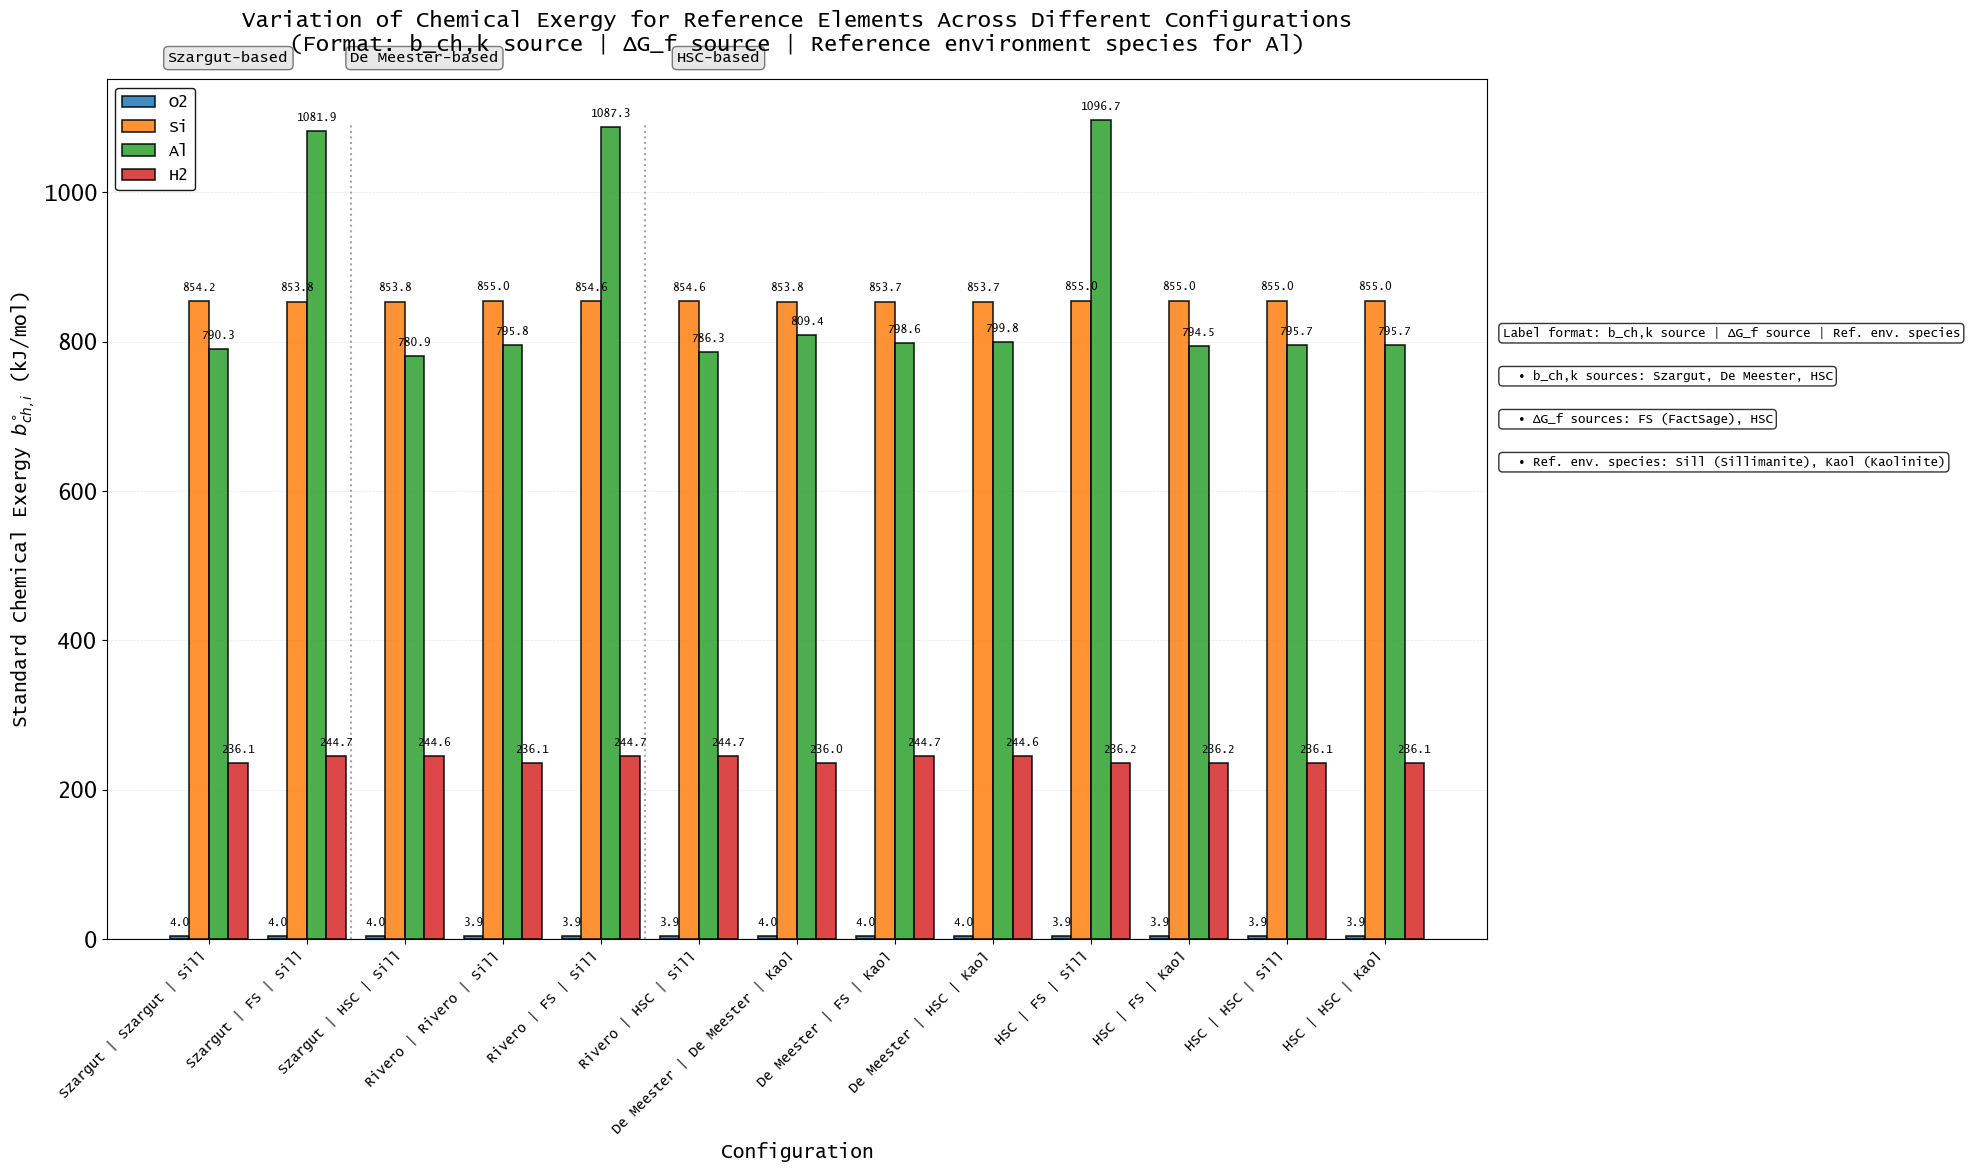


TABLE: Standard chemical exergy of reference elements (b_chi) for all configurations
Configuration (b_ch,k | ΔG_f | Ref.Env.) b_O2 (kJ/mol)        b_Si (kJ/mol)        b_Al (kJ/mol)        b_H2 (kJ/mol)       
----------------------------------------------------------------------------------------------------
Szargut | Szargut | Sill                 3.97                 854.17               790.34               236.09              
Szargut | FS | Sill                      3.97                 853.79               1081.86              244.69              
Szargut | HSC | Sill                     3.97                 853.75               780.88               244.65              
Rivero | Rivero | Sill                   3.92                 855.01               795.75               236.12              
Rivero | FS | Sill                       3.92                 854.63               1087.26              244.72              
Rivero | HSC | Sill                      3.92                 8

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Define all configurations with detailed metadata
configurations = [
    {
        "name": "Szargut + Szargut",
        "chem_exergy_source": "Szargut",
        "DeltafrG_source": "Szargut",
        "env_species_Al": "Sillimanite",
        "short_label": "Szargut | Szargut | Sill",
        "chem_exergy_k": szargut_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_szargut_brgm,
        "b_chk_init": szargut_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "Szargut + FactSage",
        "chem_exergy_source": "Szargut",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Sillimanite",
        "short_label": "Szargut | FS | Sill",
        "chem_exergy_k": szargut_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": szargut_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "Szargut + HSC",
        "chem_exergy_source": "Szargut",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Sillimanite",
        "short_label": "Szargut | HSC | Sill",
        "chem_exergy_k": szargut_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": szargut_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "Rivero + Rivero",
        "chem_exergy_source": "Rivero",
        "DeltafrG_source": "Rivero",
        "env_species_Al": "Sillimanite",
        "short_label": "Rivero | Rivero | Sill",
        "chem_exergy_k": rivero_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_rivero_brgm,
        "b_chk_init": rivero_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "Rivero + FactSage",
        "chem_exergy_source": "Rivero",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Sillimanite",
        "short_label": "Rivero | FS | Sill",
        "chem_exergy_k": rivero_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": rivero_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "Rivero + HSC",
        "chem_exergy_source": "Rivero",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Sillimanite",
        "short_label": "Rivero | HSC | Sill",
        "chem_exergy_k": rivero_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": rivero_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "De Meester + De Meester",
        "chem_exergy_source": "De Meester",
        "DeltafrG_source": "De Meester",
        "env_species_Al": "Kaolinite",
        "short_label": "De Meester | De Meester | Kaol",
        "chem_exergy_k": demeester_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_demeester_brgm,
        "b_chk_init": demeester_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
        "name": "De Meester + FactSage",
        "chem_exergy_source": "De Meester",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Kaolinite",
        "short_label": "De Meester | FS | Kaol",
        "chem_exergy_k": demeester_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": demeester_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
        "name": "De Meester + HSC",
        "chem_exergy_source": "De Meester",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Kaolinite",
        "short_label": "De Meester | HSC | Kaol",
        "chem_exergy_k": demeester_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": demeester_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
    "name": "HSC + FactSage (Sillimanite)",
    "chem_exergy_source": "HSC",
    "DeltafrG_source": "FactSage",
    "env_species_Al": "Sillimanite",
    "short_label": "HSC | FS | Sill",
    "chem_exergy_k": HSC_chem_exergy_k,
    "DeltafrG_std": DeltafrG_std_FS,
    "b_chk_init": HSC_chem_exergy_i,
    "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "HSC + FactSage (Kaolinite)",
        "chem_exergy_source": "HSC",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Kaolinite",
        "short_label": "HSC | FS | Kaol",
        "chem_exergy_k": HSC_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": HSC_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
        "name": "HSC + HSC (Sillimanite)",
        "chem_exergy_source": "HSC",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Sillimanite",
        "short_label": "HSC | HSC | Sill",
        "chem_exergy_k": HSC_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": HSC_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "HSC + HSC (Kaolinite)",
        "chem_exergy_source": "HSC",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Kaolinite",
        "short_label": "HSC | HSC | Kaol",
        "chem_exergy_k": HSC_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": HSC_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
]

# Compute b_chi for all configurations
results_all_configs = []
for config in configurations:
    b_chi = compute_b_chi_sequential(
        chem_exergy_k=config["chem_exergy_k"],
        DeltafrG_std=config["DeltafrG_std"],
        standard_state_equivalencies=standard_state_equivalencies,
        b_chk_init=config["b_chk_init"],
        env_species_order=config["env_species_order"],
    )
    results_all_configs.append({
        "name": config["name"],
        "short_label": config["short_label"],
        "chem_exergy_source": config["chem_exergy_source"],
        "DeltafrG_source": config["DeltafrG_source"],
        "env_species_Al": config["env_species_Al"],
        "b_chi": b_chi,
    })

# Extract b_chi values
b_chi_values = []
for result in results_all_configs:
    b_chi_values.append({
        "short_label": result["short_label"],
        "b_O2": result["b_chi"]["O2"],
        "b_Si": result["b_chi"]["Si"],
        "b_Al": result["b_chi"]["Al"],
        "b_H2": result["b_chi"].get("H2", None),
    })

df_b_chi = pd.DataFrame(b_chi_values)
df_b_chi["b_H2"] = df_b_chi["b_H2"].fillna(0)

# Create single comprehensive plot
fig, ax = plt.subplots(figsize=(20, 12))

# Set up bar positions
x = np.arange(len(df_b_chi))
width = 0.2
multiplier = 0

# Define colors for each element
colors = {
    'b_O2': '#1f77b4',  # blue
    'b_Si': '#ff7f0e',  # orange
    'b_Al': '#2ca02c',  # green
    'b_H2': '#d62728'   # red
}

# Plot bars for each element
for element, color in colors.items():
    offset = width * multiplier
    values = df_b_chi[element].values
    bars = ax.bar(x + offset, values, width, label=element.replace('b_', ''), 
                  color=color, edgecolor='black', linewidth=1.2, alpha=0.85)
    
    # Add value labels on top of bars (only for positive values)
    for bar, val in zip(bars, values):
        # Convert val to float if it's numeric, skip if it's not
        try:
            val_float = float(val)
            if val_float > 0:
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height + max(df_b_chi[['b_O2', 'b_Si', 'b_Al', 'b_H2']].max()) * 0.01,
                    f'{val_float:.1f}', ha='center', va='bottom', fontsize=8, rotation=0, fontweight='bold')
        except (ValueError, TypeError):
            pass  # Skip non-numeric values (like "—") 
    multiplier += 1

# Customize the plot
ax.set_xlabel('Configuration', fontsize=14, fontweight='bold')
ax.set_ylabel('Standard Chemical Exergy $b_{ch,i}^{\\circ}$ (kJ/mol)', fontsize=14, fontweight='bold')
ax.set_title('Variation of Chemical Exergy for Reference Elements Across Different Configurations\n(Format: b_ch,k source | ΔG_f source | Reference environment species for Al)', 
             fontsize=16, fontweight='bold', pad=20)

# Set x-ticks with short labels
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(df_b_chi['short_label'], rotation=45, ha='right', fontsize=10)

# Add legend
ax.legend(loc='upper left', fontsize=12, framealpha=0.9, edgecolor='black')

# Add grid
ax.grid(axis='y', linestyle='--', alpha=0.3, linewidth=0.5)
ax.set_axisbelow(True)

# Add horizontal line at y=0 if needed
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)

# Add background shading to separate different b_ch,k sources
y_min, y_max = ax.get_ylim()
y_range = y_max - y_min

# Add annotations for grouping
bbox_props = dict(boxstyle="round,pad=0.3", facecolor="lightgray", alpha=0.5)

# Group 1: Szargut based
ax.text(0.5, y_max + y_range*0.02, 'Szargut-based', ha='center', fontsize=11, 
        fontweight='bold', bbox=bbox_props)

# Group 2: De Meester based
ax.text(2.5, y_max + y_range*0.02, 'De Meester-based', ha='center', fontsize=11, 
        fontweight='bold', bbox=bbox_props)

# Group 3: HSC based
ax.text(5.5, y_max + y_range*0.02, 'HSC-based', ha='center', fontsize=11, 
        fontweight='bold', bbox=bbox_props)

# Add separator lines between groups
ax.axvline(x=1.75, ymin=0, ymax=0.95, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
ax.axvline(x=4.75, ymin=0, ymax=0.95, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)

# Add color-coded legend for the short label format
legend_text = [
    "Label format: b_ch,k source | ΔG_f source | Ref. env. species",
    "  • b_ch,k sources: Szargut, De Meester, HSC",
    "  • ΔG_f sources: FS (FactSage), HSC",
    "  • Ref. env. species: Sill (Sillimanite), Kaol (Kaolinite)"
]
text_x = x[-1] + 1.5
text_y = y_max - y_range*0.3
for i, text in enumerate(legend_text):
    ax.text(text_x, text_y - i*y_range*0.05, text, fontsize=9, 
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

# Adjust layout
plt.tight_layout()

# Save as SVG
plt.savefig('chemical_exergy_variation_all_configurations.svg', format='svg', dpi=300, bbox_inches='tight')
#  plt.savefig('chemical_exergy_variation_all_configurations.png', dpi=300, bbox_inches='tight')

plt.show()

# Print the detailed table
print("\n" + "="*100)
print("TABLE: Standard chemical exergy of reference elements (b_chi) for all configurations")
print("="*100)
print(f"{'Configuration (b_ch,k | ΔG_f | Ref.Env.)':<40} {'b_O2 (kJ/mol)':<20} {'b_Si (kJ/mol)':<20} {'b_Al (kJ/mol)':<20} {'b_H2 (kJ/mol)':<20}")
print("-"*100)
for idx, row in df_b_chi.iterrows():
    print(f"{row['short_label']:<40} {row['b_O2']:<20.2f} {row['b_Si']:<20.2f} {row['b_Al']:<20.2f} {row['b_H2']:<20.2f}")
print("="*100)

# Statistical analysis
print("\n" + "="*100)
print("STATISTICAL ANALYSIS")
print("="*100)
for element in ['b_O2', 'b_Si', 'b_Al', 'b_H2']:
    values = df_b_chi[element].values
    if np.all(values == 0):
        continue
    print(f"\n{element.replace('b_', '')}:")
    print(f"  Mean: {np.mean(values):.2f} kJ/mol")
    print(f"  Std Dev: {np.std(values):.2f} kJ/mol")
    print(f"  Min: {np.min(values):.2f} kJ/mol")
    print(f"  Max: {np.max(values):.2f} kJ/mol")
    print(f"  Range: {np.max(values) - np.min(values):.2f} kJ/mol")

# 📰 Fig. 4

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


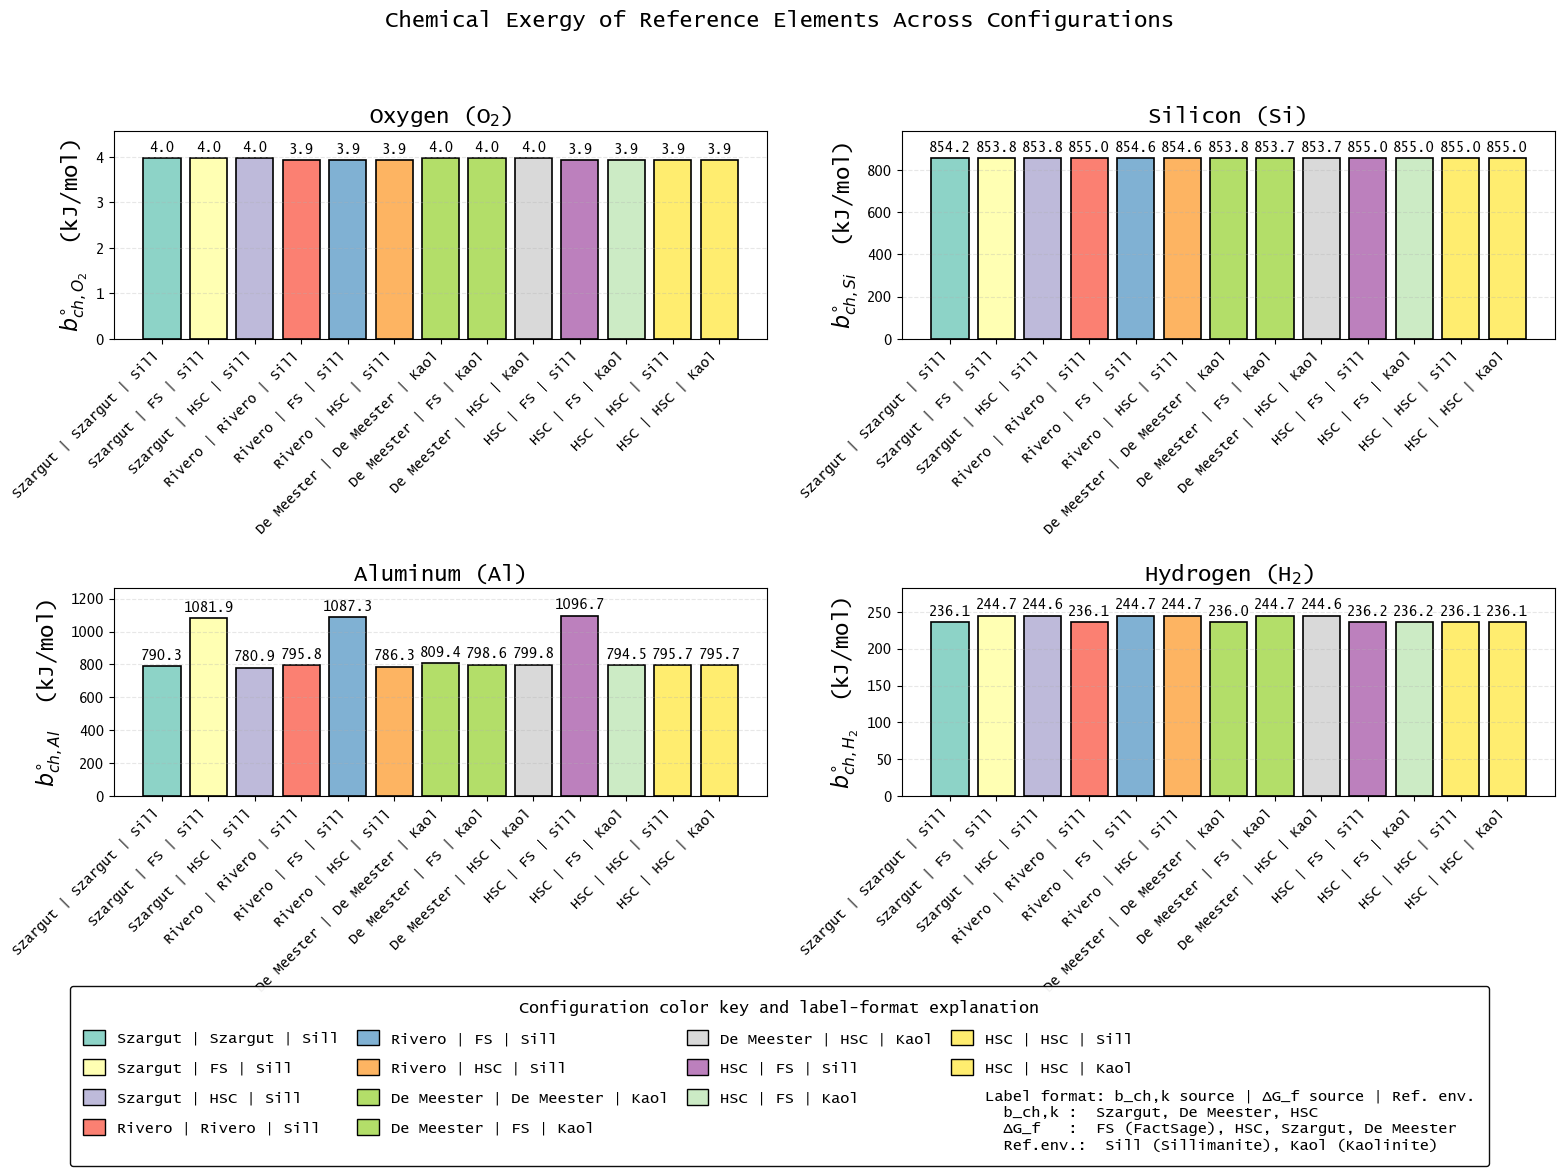


TABLE: Standard chemical exergy of reference elements (b_chi) for all configurations
Configuration (b_ch,k | ΔG_f | Ref.Env.) O₂ (kJ/mol)          Si (kJ/mol)          Al (kJ/mol)          H₂ (kJ/mol)         
----------------------------------------------------------------------------------------------------
Szargut | Szargut | Sill                 3.97                 854.17               790.34               236.09              
Szargut | FS | Sill                      3.97                 853.79               1081.86              244.69              
Szargut | HSC | Sill                     3.97                 853.75               780.88               244.65              
Rivero | Rivero | Sill                   3.92                 855.01               795.75               236.12              
Rivero | FS | Sill                       3.92                 854.63               1087.26              244.72              
Rivero | HSC | Sill                      3.92                 8

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

# ============================================================
# --- GRAPHICS PROGRAM STATEMENT (for JIE/Springer submission) ---
# ============================================================
# All figures were created with Python 3 / Matplotlib and NumPy
# and exported as EPS, PDF, TIFF and SVG.
# Fonts are embedded (TrueType) in the EPS and PDF outputs.
GRAPHICS_PROGRAM = "Created with Python 3 + Matplotlib + NumPy"

# ============================================================
# --- Unified Font & Text Settings (Lucida Console ONLY) ---
# ============================================================
plt.rcParams["font.family"]    = "monospace"
plt.rcParams["font.monospace"] = ["Lucida Console", "DejaVu Sans Mono"]

# Embed TrueType fonts (required by Springer for vector EPS/PDF)
plt.rcParams["ps.fonttype"]    = 42
plt.rcParams["pdf.fonttype"]   = 42
plt.rcParams["svg.fonttype"]   = "none"

FONT_SIZE         = 16
FONT_TITLE        = 16
FONT_LABEL        = 16
FONT_TICK         = 10
FONT_XTICK        = 10
FONT_LEGEND       = 11
FONT_LEGEND_TITLE = 12
FONT_SUPTITLE     = 16
FONT_CAPTION      = 10

plt.rcParams["font.size"] = FONT_SIZE

# ============================================================
# --- Ensure H2 is numeric ---
# ============================================================
df_b_chi['b_H2'] = pd.to_numeric(df_b_chi['b_H2'], errors='coerce').fillna(0)

# ============================================================
# --- 4 subplots (one per element) ---
# ============================================================
elements = ['b_O2', 'b_Si', 'b_Al', 'b_H2']
titles   = ['Oxygen (O$_2$)', 'Silicon (Si)', 'Aluminum (Al)', 'Hydrogen (H$_2$)']
ylabels  = [
    r'$b_{ch,O_2}^{\circ}$  (kJ/mol)',
    r'$b_{ch,Si}^{\circ}$  (kJ/mol)',
    r'$b_{ch,Al}^{\circ}$  (kJ/mol)',
    r'$b_{ch,H_2}^{\circ}$  (kJ/mol)',
]

# --- Fixed color per configuration (same color = same config everywhere) ---
config_labels = df_b_chi['short_label'].tolist()
n_configs     = len(config_labels)
colors        = plt.cm.Set3(np.linspace(0, 1, n_configs))
config_colors = dict(zip(config_labels, colors))

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(
    'Chemical Exergy of Reference Elements Across Configurations',
    fontsize=FONT_SUPTITLE,
    fontweight='bold',
)

for idx, (element, title, ylabel) in enumerate(zip(elements, titles, ylabels)):
    ax = axes[idx // 2, idx % 2]

    values = df_b_chi[element].values
    labels = df_b_chi['short_label'].values
    bar_colors = [config_colors[l] for l in labels]

    bars = ax.bar(
        range(len(values)),
        values,
        color=bar_colors,
        edgecolor='black',
        linewidth=1.2,
    )

    # Value labels on top of bars
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(values) * 0.02,
                f'{val:.1f}',
                ha='center', va='bottom',
                fontsize=FONT_TICK,
                fontweight='bold',
            )

    # Customize the plot
    ax.set_ylabel(ylabel, fontsize=FONT_LABEL, fontweight='bold')
    ax.set_title(title,  fontsize=FONT_TITLE, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=FONT_XTICK)
    ax.tick_params(axis='y', labelsize=FONT_TICK)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_ylim(0, max(values) * 1.15)

plt.tight_layout(rect=[0, 0.14, 1, 0.96])

# ============================================================
# --- SHARED BOX LEGEND (colors + label-format explanation) ---
# ============================================================
# Color patches: one per configuration
color_handles = [
    mpatches.Patch(facecolor=config_colors[l], edgecolor='black', label=l)
    for l in config_labels
]

# Explanatory "dummy" handle that occupies one legend slot
explanation_text = (
    'Label format: b_ch,k source | ΔG_f source | Ref. env.\n'
    '  b_ch,k :  Szargut, De Meester, HSC\n'
    '  ΔG_f   :  FS (FactSage), HSC, Szargut, De Meester\n'
    '  Ref.env.:  Sill (Sillimanite), Kaol (Kaolinite)'
)
explanation_handle = mpatches.Patch(
    facecolor='white', edgecolor='white', label=explanation_text
)

# Build a single framed legend below the figure
all_handles = color_handles + [explanation_handle]

leg = fig.legend(
    handles=all_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    ncol=min(n_configs, 4),
    fontsize=FONT_LEGEND,
    title='Configuration color key and label-format explanation',
    title_fontsize=FONT_LEGEND_TITLE,
    frameon=True,
    fancybox=True,
    framealpha=0.95,
    edgecolor='black',
    handlelength=1.4,
    handleheight=1.2,
    columnspacing=1.2,
    labelspacing=0.9,
    borderpad=0.9,
)
leg.get_frame().set_linewidth(1.0)
leg.get_title().set_fontweight('bold')

plt.savefig('Fig4.eps',  format='eps',  dpi=600, bbox_inches='tight')
plt.savefig('Fig4.pdf',  format='pdf',  dpi=600, bbox_inches='tight')
plt.savefig('Fig4.tiff', format='tiff', dpi=600, bbox_inches='tight',
            pil_kwargs={"compression": "tiff_lzw"})
plt.savefig('Fig4.svg',  format='svg',  dpi=600, bbox_inches='tight')

plt.show()

# ============================================================
# --- Print the table ---
# ============================================================
print("\n" + "=" * 100)
print("TABLE: Standard chemical exergy of reference elements (b_chi) for all configurations")
print("=" * 100)
print(f"{'Configuration (b_ch,k | ΔG_f | Ref.Env.)':<40} "
      f"{'O₂ (kJ/mol)':<20} {'Si (kJ/mol)':<20} {'Al (kJ/mol)':<20} {'H₂ (kJ/mol)':<20}")
print("-" * 100)
for idx, row in df_b_chi.iterrows():
    print(f"{row['short_label']:<40} "
          f"{row['b_O2']:<20.2f} {row['b_Si']:<20.2f} "
          f"{row['b_Al']:<20.2f} {row['b_H2']:<20.2f}")
print("=" * 100)

print("\n" + "-" * 100)
print("GRAPHICS PROGRAM STATEMENT (paste into cover letter / figure caption):")
print(f"  {GRAPHICS_PROGRAM}")
print("  Fonts: Lucida Console (fallback DejaVu Sans Mono), embedded as TrueType in EPS/PDF.")
print("  Formats supplied: EPS (primary), PDF (backup), TIFF 600 dpi (raster), SVG (editable).")
print("-" * 100)

# 📰 Fig. 5
SRS B_ch: variables contrib to discrepancies


PAIRED-EFFECTS ANALYSIS
   element       factor  n_pairs  mean_effect  std_effect  max_effect
0       O2  b_ch_source        4        0.050       0.000       0.050
1       O2    dG_source        5        0.000       0.000       0.000
2       O2      ref_env        2        0.000       0.000       0.000
3       Si  b_ch_source        4        1.275       0.035       1.310
4       Si    dG_source        5        0.202       0.176       0.415
5       Si      ref_env        2        0.000       0.000       0.000
6       Al  b_ch_source        4        9.445       5.377      14.822
7       Al    dG_source        5      182.976     144.555     300.979
8       Al      ref_env        2      151.070     151.065     302.135
9       H2  b_ch_source        4        8.538       0.013       8.550
10      H2    dG_source        5        5.198       4.204       8.690
11      H2      ref_env        2        0.000       0.000       0.000


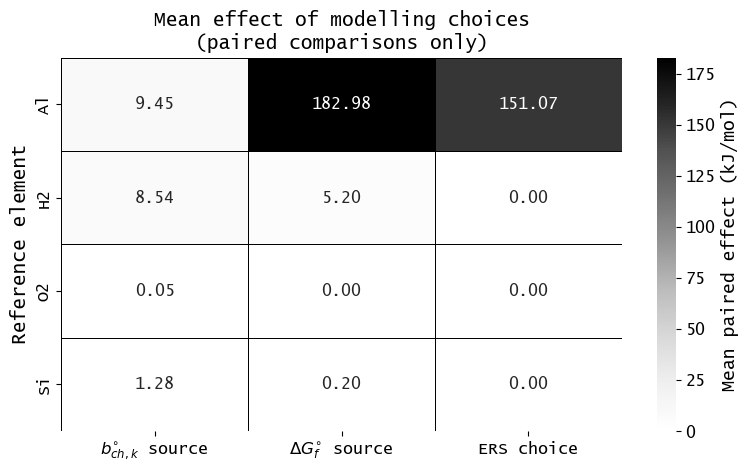

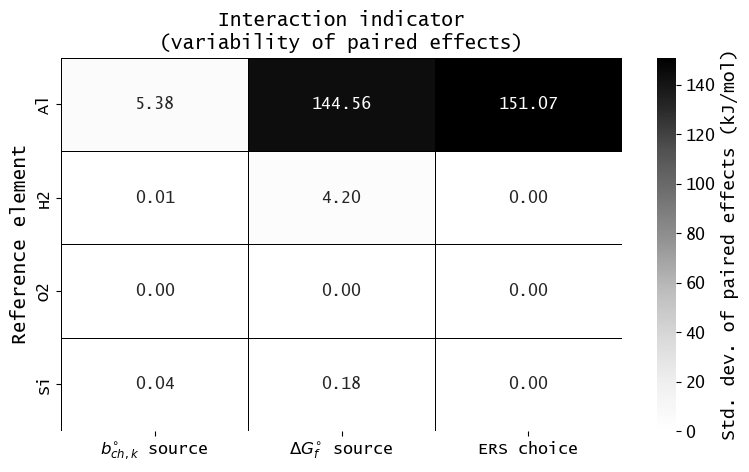


----------------------------------------------------------------------------------------------------
GRAPHICS PROGRAM STATEMENT (paste into cover letter / figure caption):
  Created with Python 3 + Matplotlib + Seaborn + NumPy
  Fonts: Lucida Console (fallback DejaVu Sans Mono), embedded as TrueType in EPS/PDF.
  Formats supplied: EPS (primary), PDF (backup), TIFF 600 dpi (raster), SVG (editable).
----------------------------------------------------------------------------------------------------


In [79]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ============================================================
# --- GRAPHICS PROGRAM STATEMENT (for JIE/Springer submission) ---
# ============================================================
# All figures were created with Python 3 / Matplotlib / Seaborn / NumPy
# and exported as EPS, PDF, TIFF and SVG.
# Fonts are embedded (TrueType) in the EPS and PDF outputs.
GRAPHICS_PROGRAM = "Created with Python 3 + Matplotlib + Seaborn + NumPy"

# ============================================================
# --- Unified Font & Text Settings (Lucida Console ONLY) ---
# ============================================================
plt.rcParams["font.family"]    = "monospace"
plt.rcParams["font.monospace"] = ["Lucida Console", "DejaVu Sans Mono"]

# Embed TrueType fonts (required by Springer for vector EPS/PDF)
plt.rcParams["ps.fonttype"]    = 42
plt.rcParams["pdf.fonttype"]   = 42
plt.rcParams["svg.fonttype"]   = "none"

FONT_SIZE         = 16
FONT_TITLE        = 14
FONT_LABEL        = 14
FONT_TICK         = 12
FONT_ANNOT        = 12     # heatmap cell numbers
FONT_CBAR_LABEL   = 13
FONT_SUPTITLE     = 16
FONT_CAPTION      = 10

plt.rcParams["font.size"] = FONT_SIZE

# ============================================================
# --- PREPARE DATA ---
# ============================================================
df = df_b_chi.copy()

split = (
    df['short_label']
    .str.split('|', expand=True, regex=False)
    .apply(lambda x: x.str.strip())
)
split.columns = ['b_ch_source', 'dG_source', 'ref_env']
df[['b_ch_source', 'dG_source', 'ref_env']] = split

df['ref_env'] = df['ref_env'].replace({
    'Sill': 'Sillimanite',
    'Kaol': 'Kaolinite',
})
df['dG_source'] = df['dG_source'].replace({'FS': 'FactSage'})

# ============================================================
# --- LONG FORMAT ---
# ============================================================
df_long = df.melt(
    id_vars=['b_ch_source', 'dG_source', 'ref_env'],
    value_vars=['b_O2', 'b_Si', 'b_Al', 'b_H2'],
    var_name='element',
    value_name='b_ch',
)
df_long['element'] = df_long['element'].str.replace('b_', '', regex=False)

# ============================================================
# --- PAIRED-EFFECTS FUNCTION ---
# ============================================================
def compute_paired_effects(data, factor, control_factors):
    """Paired effects of one factor while holding control_factors fixed."""
    effects = []
    for _, group in data.groupby(control_factors):
        if group[factor].nunique() < 2:
            continue
        values = group['b_ch'].values
        effects.append(np.max(values) - np.min(values))
    return effects

# ============================================================
# --- ANALYSIS ---
# ============================================================
elements = ['O2', 'Si', 'Al', 'H2']
analysis = []
factor_definitions = {
    'b_ch_source': ['dG_source', 'ref_env'],
    'dG_source':   ['b_ch_source', 'ref_env'],
    'ref_env':     ['b_ch_source', 'dG_source'],
}

for element in elements:
    dfe = df_long[df_long['element'] == element].copy()
    for factor, controls in factor_definitions.items():
        effects = compute_paired_effects(dfe, factor, controls)
        if len(effects) == 0:
            mean_effect, std_effect, max_effect = np.nan, np.nan, np.nan
        else:
            mean_effect = np.mean(effects)
            std_effect  = np.std(effects)
            max_effect  = np.max(effects)
        analysis.append([element, factor, len(effects),
                         mean_effect, std_effect, max_effect])

results = pd.DataFrame(
    analysis,
    columns=['element', 'factor', 'n_pairs',
             'mean_effect', 'std_effect', 'max_effect'],
)

# ============================================================
# --- PRINT TABLE ---
# ============================================================
print("\n" + "=" * 80)
print("PAIRED-EFFECTS ANALYSIS")
print("=" * 80)
print(results.round(3))

# ----------------------------------------------------------
# Shared axis-label mapping
# ----------------------------------------------------------
factor_rename = {
    'b_ch_source': r'$b_{ch,k}^{\circ}$ source',
    'dG_source':   r'$\Delta G_f^{\circ}$ source',
    'ref_env':     'ERS choice',
}

# ============================================================
# --- FIGURE 1: MEAN PAIRED EFFECT (grayscale, journal-safe) ---
# ============================================================
heatmap_mean = results.pivot(index='element', columns='factor',
                             values='mean_effect').rename(columns=factor_rename)

fig1, ax1 = plt.subplots(figsize=(8, 5))
sns.heatmap(
    heatmap_mean,
    annot=True, fmt='.2f',
    cmap='Greys',
    linewidths=0.6,
    linecolor='black',
    annot_kws={'fontsize': FONT_ANNOT, 'fontweight': 'bold'},
    cbar_kws={'label': 'Mean paired effect (kJ/mol)'},
    ax=ax1,
)
ax1.set_title('Mean effect of modelling choices\n(paired comparisons only)',
              fontsize=FONT_TITLE, fontweight='bold')
ax1.set_xlabel('')
ax1.set_ylabel('Reference element', fontsize=FONT_LABEL)
ax1.tick_params(axis='both', labelsize=FONT_TICK)

# Style the colorbar label font
cbar1 = ax1.collections[0].colorbar
cbar1.set_label('Mean paired effect (kJ/mol)', fontsize=FONT_CBAR_LABEL)
cbar1.ax.tick_params(labelsize=FONT_TICK)

plt.tight_layout()
fig1.savefig('paired_effects_heatmap.eps',  format='eps',  dpi=600, bbox_inches='tight')
fig1.savefig('paired_effects_heatmap.pdf',  format='pdf',  dpi=600, bbox_inches='tight')
fig1.savefig('paired_effects_heatmap.tiff', format='tiff', dpi=600, bbox_inches='tight',
             pil_kwargs={"compression": "tiff_lzw"})
fig1.savefig('paired_effects_heatmap.svg',  format='svg',  dpi=600, bbox_inches='tight')
plt.show()

# ============================================================
# --- FIGURE 2: INTERACTION INDICATOR (grayscale, journal-safe) ---
# ============================================================
heatmap_interaction = results.pivot(index='element', columns='factor',
                                    values='std_effect').rename(columns=factor_rename)

fig2, ax2 = plt.subplots(figsize=(8, 5))
sns.heatmap(
    heatmap_interaction,
    annot=True, fmt='.2f',
    cmap='Greys',
    linewidths=0.6,
    linecolor='black',
    annot_kws={'fontsize': FONT_ANNOT, 'fontweight': 'bold'},
    cbar_kws={'label': 'Std. dev. of paired effects (kJ/mol)'},
    ax=ax2,
)
ax2.set_title('Interaction indicator\n(variability of paired effects)',
              fontsize=FONT_TITLE, fontweight='bold')
ax2.set_xlabel('')
ax2.set_ylabel('Reference element', fontsize=FONT_LABEL)
ax2.tick_params(axis='both', labelsize=FONT_TICK)

cbar2 = ax2.collections[0].colorbar
cbar2.set_label('Std. dev. of paired effects (kJ/mol)', fontsize=FONT_CBAR_LABEL)
cbar2.ax.tick_params(labelsize=FONT_TICK)

plt.tight_layout()
fig2.savefig('Fig5.eps',  format='eps',  dpi=600, bbox_inches='tight')
fig2.savefig('Fig5.pdf',  format='pdf',  dpi=600, bbox_inches='tight')
fig2.savefig('Fig5.tiff', format='tiff', dpi=600, bbox_inches='tight',
             pil_kwargs={"compression": "tiff_lzw"})
fig2.savefig('Fig5.svg',  format='svg',  dpi=600, bbox_inches='tight')
plt.show()

# ============================================================
# --- Graphics program statement ---
# ============================================================
print("\n" + "-" * 100)
print("GRAPHICS PROGRAM STATEMENT (paste into cover letter / figure caption):")
print(f"  {GRAPHICS_PROGRAM}")
print("  Fonts: Lucida Console (fallback DejaVu Sans Mono), embedded as TrueType in EPS/PDF.")
print("  Formats supplied: EPS (primary), PDF (backup), TIFF 600 dpi (raster), SVG (editable).")
print("-" * 100)

## Al Focus

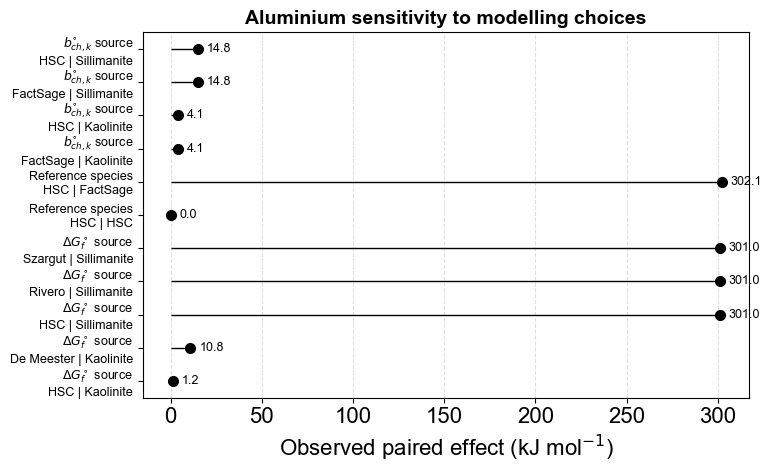

In [65]:
# ==========================================================
# ALUMINIUM PAIRED-COMPARISON DOT PLOT
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

al = df_long[df_long["element"] == "Al"].copy()

comparisons = []

# ----------------------------------------------------------
# ΔG source effect
# ----------------------------------------------------------

for (bch, env), grp in al.groupby(
    ["b_ch_source", "ref_env"]
):

    if grp["dG_source"].nunique() < 2:
        continue

    effect = (
        grp["b_ch"].max()
        - grp["b_ch"].min()
    )

    comparisons.append({
        "factor": r"$\Delta G_f^\circ$ source",
        "context": f"{bch} | {env}",
        "effect": effect
    })

# ----------------------------------------------------------
# Reference species effect
# ----------------------------------------------------------

for (bch, dg), grp in al.groupby(
    ["b_ch_source", "dG_source"]
):

    if grp["ref_env"].nunique() < 2:
        continue

    effect = (
        grp["b_ch"].max()
        - grp["b_ch"].min()
    )

    comparisons.append({
        "factor": "Reference species",
        "context": f"{bch} | {dg}",
        "effect": effect
    })

# ----------------------------------------------------------
# bch,k source effect
# ----------------------------------------------------------

for (dg, env), grp in al.groupby(
    ["dG_source", "ref_env"]
):

    if grp["b_ch_source"].nunique() < 2:
        continue

    effect = (
        grp["b_ch"].max()
        - grp["b_ch"].min()
    )

    comparisons.append({
        "factor": r"$b_{ch,k}^{\circ}$ source",
        "context": f"{dg} | {env}",
        "effect": effect
    })

forest = pd.DataFrame(comparisons)

# ----------------------------------------------------------
# SORT FOR DISPLAY
# ----------------------------------------------------------

factor_order = [
    r"$\Delta G_f^\circ$ source",
    "Reference species",
    r"$b_{ch,k}^{\circ}$ source"
]

forest["factor"] = pd.Categorical(
    forest["factor"],
    categories=factor_order,
    ordered=True
)

forest = forest.sort_values(
    ["factor", "effect"]
)

# ----------------------------------------------------------
# BUILD Y LABELS
# ----------------------------------------------------------

labels = forest.apply(
    lambda row: f"{row['factor']}\n{row['context']}",
    axis=1
)
# ----------------------------------------------------------
# PLOT
# ----------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5)
)

y = np.arange(len(forest))

# horizontal guide lines

for yi, effect in zip(y, forest["effect"]):

    ax.hlines(
        yi,
        xmin=0,
        xmax=effect,
        color="black",
        linewidth=1
    )

# dots

ax.plot(
    forest["effect"],
    y,
    "o",
    color="black",
    markersize=7
)

# effect labels

for yi, effect in zip(y, forest["effect"]):

    ax.text(
        effect + 5,
        yi,
        f"{effect:.1f}",
        va="center",
        fontsize=9
    )

ax.set_yticks(y)

ax.set_yticklabels(
    labels,
    fontsize=9
)

ax.set_xlabel(
    "Observed paired effect (kJ mol$^{-1}$)"
)

ax.set_title(
    "Aluminium sensitivity to modelling choices",
    fontsize=14,
    fontweight="bold"
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "aluminium_paired_effects.svg",
    bbox_inches="tight"
)

# plt.savefig(
#     "aluminium_paired_effects.png",
#     dpi=600,
#     bbox_inches="tight"
# )

plt.show()

# 📊 6 Gs Representations
For Al2O3

### Single results df

In [66]:
# Compute b_chi for FS using each exergy method's b_chk
b_chi_FS_szargut = compute_b_chi_sequential(
    chem_exergy_k=szargut_chem_exergy_k, 
    DeltafrG_std=DeltafrG_std_FS, 
    standard_state_equivalencies=standard_state_equivalencies, 
    b_chk_init=szargut_chem_exergy_i,
    env_species_order=[
        "SiO2",
        "Al2SiO5"
    ]
)

# Build the results once and plot them with the reusable function.
results_szargut = compute_all_G_values(
    DeltafrG_std=DeltafrG_std_szargut_brgm,
    S_std=S_std_brgm,
    H_std=H_std,
    G_std=G_std,
    resource=resource,
    reference_elements_i=reference_elements_i,
    reference_species_k=reference_environment_species_k_szargut,
    reaction_formation_j_from_i=reaction_formation_jfromis_sc,
    reaction_formation_j_from_k=reaction_formation_jfromks_sc_szargut,
    chem_exergy_k=szargut_chem_exergy_k,
    chem_exergy_i=szargut_chem_exergy_i,
    Tenv=Tenv,
    standard_state_equivalencies=standard_state_equivalencies
)

# results_HSC = compute_all_G_values(
#     DeltafrG_std=DeltafrG_std_HSC,
#     S_std=S_std_HSC,
#     H_std=H_std,
#     G_std=G_std,
#     resource=resource,
#     reference_elements_i=reference_elements_i,
#     reference_species_k=reference_environment_species_k_szargut,
#     reaction_formation_j_from_i=reaction_formation_jfromis_sc,
#     reaction_formation_j_from_k=reaction_formation_jfromks_sc_szargut,
#     chem_exergy_k=HSC_chem_exergy_k,
#     chem_exergy_i=HSC_chem_exergy_i,
#     Tenv=Tenv,
#     standard_state_equivalencies=standard_state_equivalencies
# )

# results_demeester = compute_all_G_values(
#     DeltafrG_std=DeltafrG_std_demeester_brgm,
#     S_std=S_std_brgm,
#     H_std=H_std,
#     G_std=G_std, 
#     resource=resource,
#     reference_elements_i=reference_elements_i,
#     reference_species_k=reference_environment_species_k_demeester,  
#     reaction_formation_j_from_i=reaction_formation_jfromis_sc,
#     reaction_formation_j_from_k=reaction_formation_jfromks_sc_demeester,
#     chem_exergy_k=demeester_chem_exergy_k,
#     chem_exergy_i=demeester_chem_exergy_i,
#     Tenv=Tenv,
#     standard_state_equivalencies=standard_state_equivalencies
# )

# results_FS_with_Szargut_Al2SiO5 = compute_all_G_values(
#     DeltafrG_std=DeltafrG_std_FS,
#     S_std=S_std_FS,
#     H_std=H_std,
#     G_std=G_std, 
#     resource=resource,
#     reference_elements_i=reference_elements_i,
#     reference_species_k=reference_environment_species_k_szargut,
#     reaction_formation_j_from_i=reaction_formation_jfromis_sc,
#     reaction_formation_j_from_k=reaction_formation_jfromks_sc_szargut,
#     chem_exergy_k=szargut_chem_exergy_k,  # Using Szargut's b_chk for FS to compute b_chi
#     chem_exergy_i=b_chi_FS_szargut,  # Using computed b_chi for FS
#     Tenv=Tenv,
#     standard_state_equivalencies=standard_state_equivalencies
# )

# results_FS_with_HSC_Al2SiO5 = compute_all_G_values(
#     DeltafrG_std=DeltafrG_std_FS,
#     S_std=S_std_FS,
#     H_std=H_std,
#     G_std=G_std, 
#     resource=resource,
#     reference_elements_i=reference_elements_i,
#     reference_species_k=reference_environment_species_k_szargut,
#     reaction_formation_j_from_i=reaction_formation_jfromis_sc,
#     reaction_formation_j_from_k=reaction_formation_jfromks_sc_szargut,
#     chem_exergy_k=szargut_chem_exergy_k,  # Using Szargut's b_chk for FS to compute b_chi
#     chem_exergy_i=b_chi_FS_HSC_Al2SiO5,  # Using computed b_chi for FS
#     Tenv=Tenv,
#     standard_state_equivalencies=standard_state_equivalencies
# )

# results_FS_with_Demeester_Al2Si2O5_OH_4 = compute_all_G_values(
#     DeltafrG_std=DeltafrG_std_FS,
#     S_std=S_std_FS,
#     H_std=H_std,
#     G_std=G_std, 
#     resource=resource,
#     reference_elements_i=reference_elements_i,
#     reference_species_k=reference_environment_species_k_demeester,
#     reaction_formation_j_from_i=reaction_formation_jfromis_sc,
#     reaction_formation_j_from_k=reaction_formation_jfromks_sc_demeester,
#     chem_exergy_k=demeester_chem_exergy_k,  # Using De Meester's b_chk for FS to compute b_chi
#     chem_exergy_i=b_chi_FS_demeester,  # Using computed b_chi for FS
#     Tenv=Tenv,
#     standard_state_equivalencies=standard_state_equivalencies
# )

# results_FS_with_HSC_Al2Si2O5_OH_4 = compute_all_G_values(
#     DeltafrG_std=DeltafrG_std_FS,
#     S_std=S_std_FS,
#     H_std=H_std,
#     G_std=G_std, 
#     resource=resource,
#     reference_elements_i=reference_elements_i,
#     reference_species_k=reference_environment_species_k_szargut,
#     reaction_formation_j_from_i=reaction_formation_jfromis_sc,
#     reaction_formation_j_from_k=reaction_formation_jfromks_sc_szargut,
#     chem_exergy_k=szargut_chem_exergy_k,  # Using Szargut's b_chk for FS to compute b_chi
#     chem_exergy_i=b_chi_FS_HSC_Al2Si2O5_OH_4,  # Using computed b_chi for FS
#     Tenv=Tenv,
#     standard_state_equivalencies=standard_state_equivalencies
# )

### single results df: plot log scale

C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_27020\2756892039.py:243: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


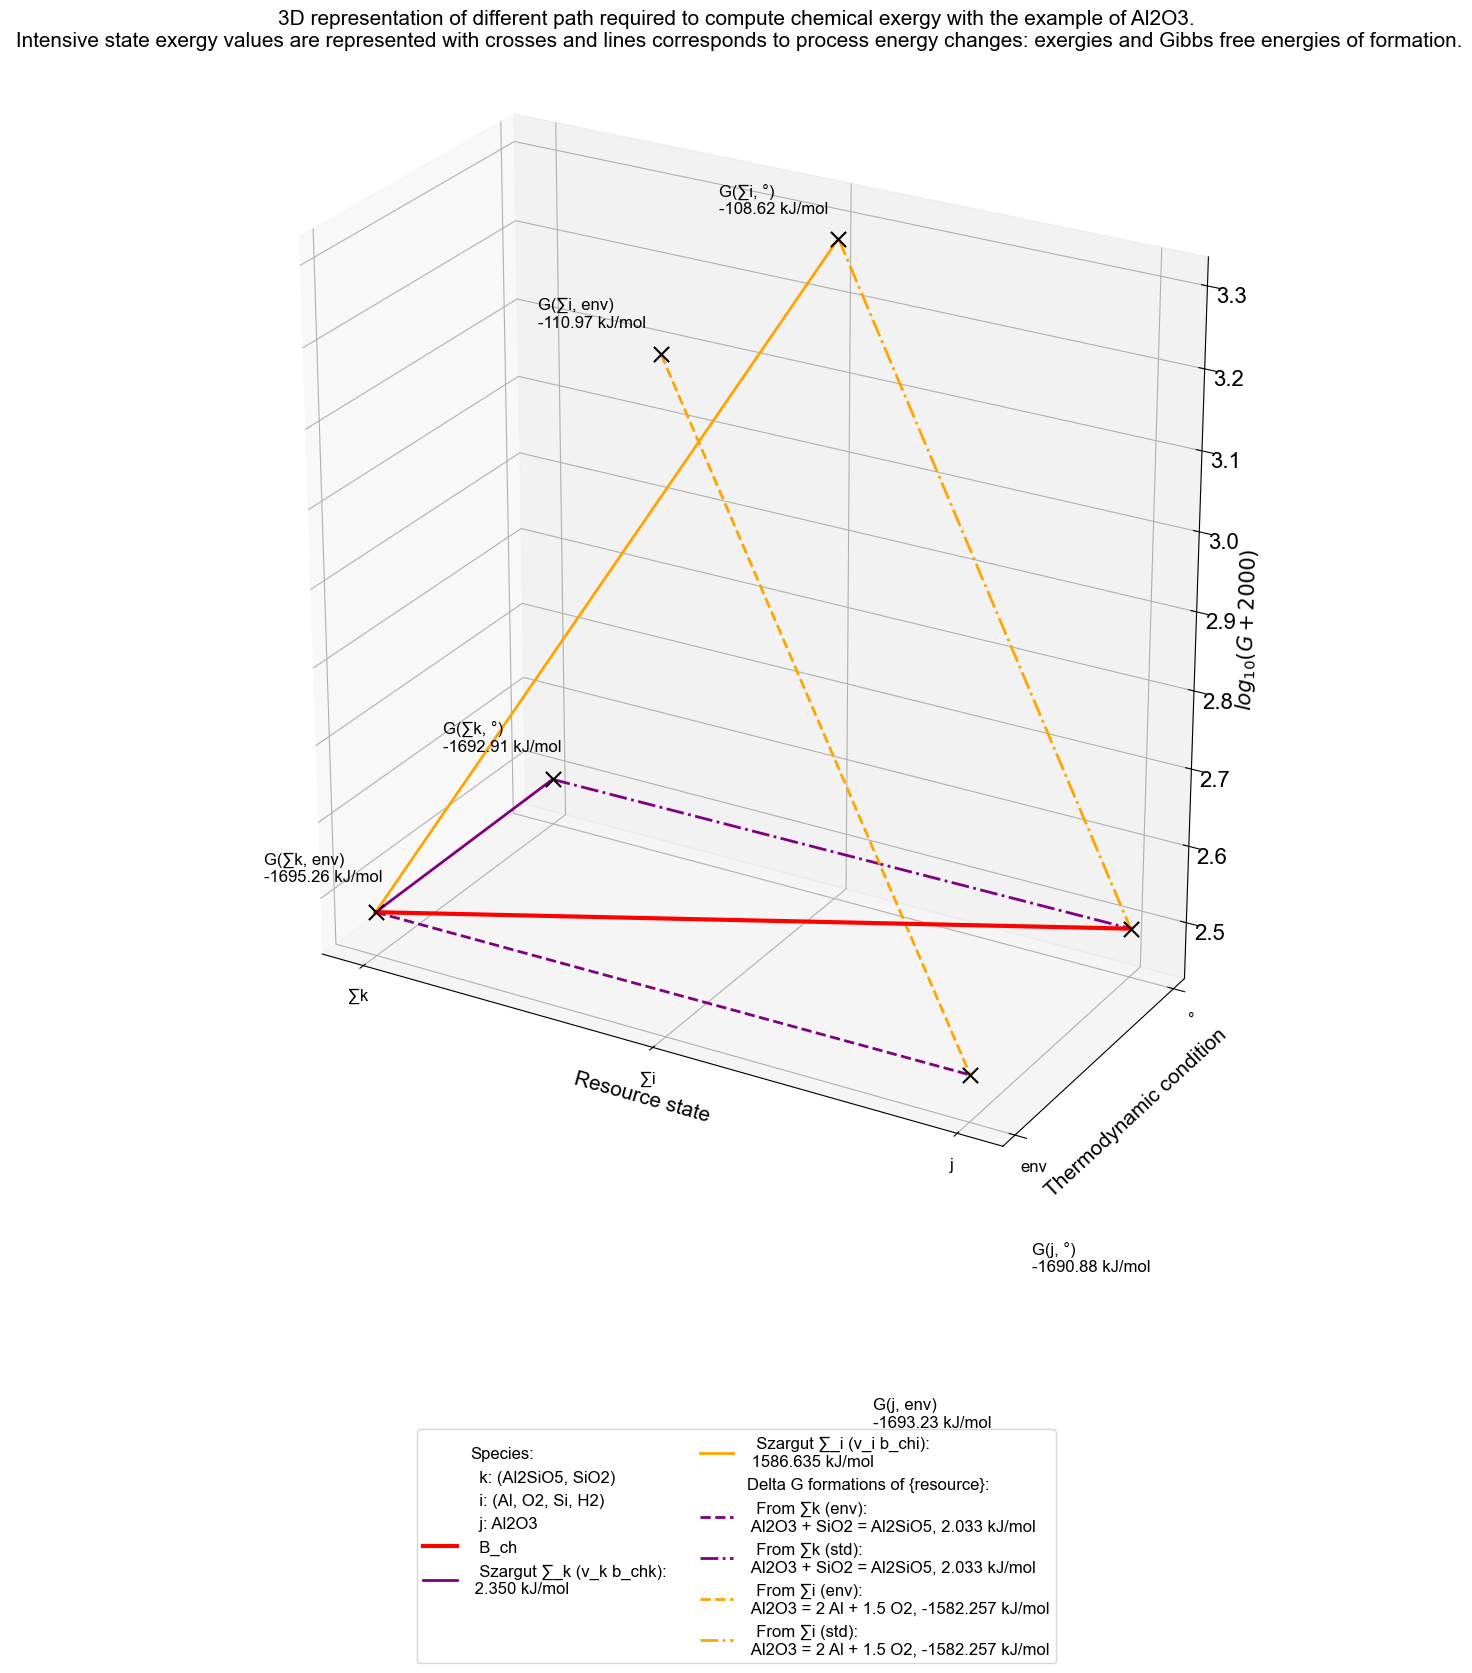

In [67]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

plt.rcParams['font.family'] = 'Arial'

fontsize_title = 15
fontsize_legend = 12

def plot_exergy_state_space_log(
    results,
    reference_elements_k,
    reference_elements_i,
    resource,
    filename='exergy_Al2O3_plot_log.svg',
    title=None
):
    """Plot the 3D exergy state-space for one computed results set."""
    if title is None:
        title = f'3D representation of different path required to compute chemical exergy with the example of {resource}.\n Intensive state exergy values are represented with crosses and lines corresponds to process energy changes: exergies and Gibbs free energies of formation.'

    G_env_sumk_in_j = results['G_env_sumk_in_j']
    G_env_j = results['G_env_j']
    G_std_sumk_in_j = results['G_std_sumk_in_j']
    G_std_j = results['G_std_j']
    G_env_sumi_in_j = results['G_env_sumi_in_j']
    G_std_sumi_in_j = results['G_std_sumi_in_j']

    x_positions = {
        '∑k': 0,
        '∑i': 1,
        'j': 2
    }

    y_positions = {
        'env': 0,
        '°': 1
    }

    color_map = {
        '∑k': 'purple',
        '∑i': 'orange',
        'j': 'black'
    }

    points = [
        ('∑k', 'env', G_env_sumk_in_j),
        ('j', 'env', G_env_j),
        ('∑k', '°', G_std_sumk_in_j),
        ('j', '°', G_std_j),
        ('∑i', 'env', G_env_sumi_in_j),
        ('∑i', '°', G_std_sumi_in_j),
    ]

    def z_transform(G):
        shifted_G = G + 2000  # Shift to make all values positive
        return np.log10(shifted_G)  # Apply log10

    fig = plt.figure(figsize=(15, 15))
    ax = fig.add_subplot(111, projection='3d')

    for state, thermo, G in points:
        x = x_positions[state]
        y = y_positions[thermo]
        z = z_transform(G)

        ax.scatter(x, y, z, s=120, marker='x', color="black")

        dx = -0.4 if state in ['∑k', '∑i'] else -0.3
        dz = 0 if state in ['∑k', '∑i'] else -0.5
        ax.text(
            x + dx,
            y,
            z + dz,
            f"G({state}, {thermo})\n{G:.2f} kJ/mol",
            fontsize=fontsize_legend,
            color="black"
        )

    sum_k = '∑k'
    sum_i = '∑i'

    ax.plot(
        [x_positions['∑k'], x_positions['∑k']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_sumk_in_j)
        ],
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['∑i']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_sumi_in_j)
        ],
        linewidth=2,
        color='orange',
        label=None
    )

    delta_G_k = G_env_j - G_env_sumk_in_j
    delta_G_i = G_env_j - G_env_sumi_in_j

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['env'], y_positions['env']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_env_j)
        ],
        linestyle='--',
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['°'], y_positions['°']],
        [
            z_transform(G_std_sumk_in_j),
            z_transform(G_std_j)
        ],
        linestyle='-.',
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑i'], x_positions['j']],
        [y_positions['env'], y_positions['env']],
        [
            z_transform(G_env_sumi_in_j),
            z_transform(G_env_j)
        ],
        linestyle='--',
        linewidth=2,
        color='orange',
        label=None
    )

    ax.plot(
        [x_positions['∑i'], x_positions['j']],
        [y_positions['°'], y_positions['°']],
        [
            z_transform(G_std_sumi_in_j),
            z_transform(G_std_j)
        ],
        linestyle='-.',
        linewidth=2,
        color='orange',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_j)
        ],
        color='red',
        linewidth=3,
        label=None
    )

    B_ch = G_std_j - G_env_sumk_in_j
    b_chk = results.get('B_sumk_in_j', None)
    b_chi = results.get('B_sumi_in_j', None)

    bch_label_z = G_env_sumk_in_j  
    ax.text(
        x_positions['∑i'] + 0.2,
        y_positions['°'] - 1.5,
        bch_label_z + 500,
        f"B_ch = {B_ch:.3f} kJ/mol",
        color='red',
        fontsize=fontsize_legend
    )

    ax.set_xlabel('Resource state', fontsize=fontsize_title)
    ax.set_ylabel('Thermodynamic condition', fontsize=fontsize_title)

    ax.set_zlabel(r'$log_{10}(G + 2000)$', fontsize=fontsize_title)

    ax.set_xticks(list(x_positions.values()))
    ax.set_xticklabels(list(x_positions.keys()), fontsize=fontsize_legend)
    ax.set_yticks(list(y_positions.values()))
    ax.set_yticklabels(list(y_positions.keys()), fontsize=fontsize_legend)
    ax.set_box_aspect((2, 1, 2))
    ax.view_init(elev=25, azim=-60)

    plt.title(title, fontsize=fontsize_title)

    import matplotlib.lines as mlines
    handles = []
    labels = []

    labels.append('Species:')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  k: ({", ".join(reference_elements_k)})')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  i: ({", ".join(reference_elements_i)})')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  j: {resource}')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append('  B_ch')
    handles.append(mlines.Line2D([0], [0], color='red', linewidth=3))

    labels.append(f'  Szargut ∑_k (ν_k b_chk):\n {b_chk:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linewidth=2))

    labels.append(f'  Szargut ∑_i (ν_i b_chi):\n {b_chi:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linewidth=2))

    labels.append('Delta G formations of {resource}:')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  From {sum_k} (env):\n Al2O3 + SiO2 = Al2SiO5, {delta_G_k:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linestyle='--', linewidth=2))

    labels.append(f'  From {sum_k} (std):\n Al2O3 + SiO2 = Al2SiO5, {delta_G_k:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linestyle='-.', linewidth=2))

    labels.append(f'  From {sum_i} (env):\n Al2O3 = 2 Al + 1.5 O2, {delta_G_i:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linestyle='--', linewidth=2))

    labels.append(f'  From {sum_i} (std):\n Al2O3 = 2 Al + 1.5 O2, {delta_G_i:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linestyle='-.', linewidth=2))

    ax.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.4), ncol=2, fontsize=fontsize_legend)
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()

plot_exergy_state_space_log(
    results_szargut,
    reference_elements_k=reference_environment_species_k_szargut,
    reference_elements_i=reference_elements_i,
    resource=resource,    filename='exergy_abs_Al2O3_plot.svg'
)

### single results df: plot raw values scale

C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_27020\155947697.py:241: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


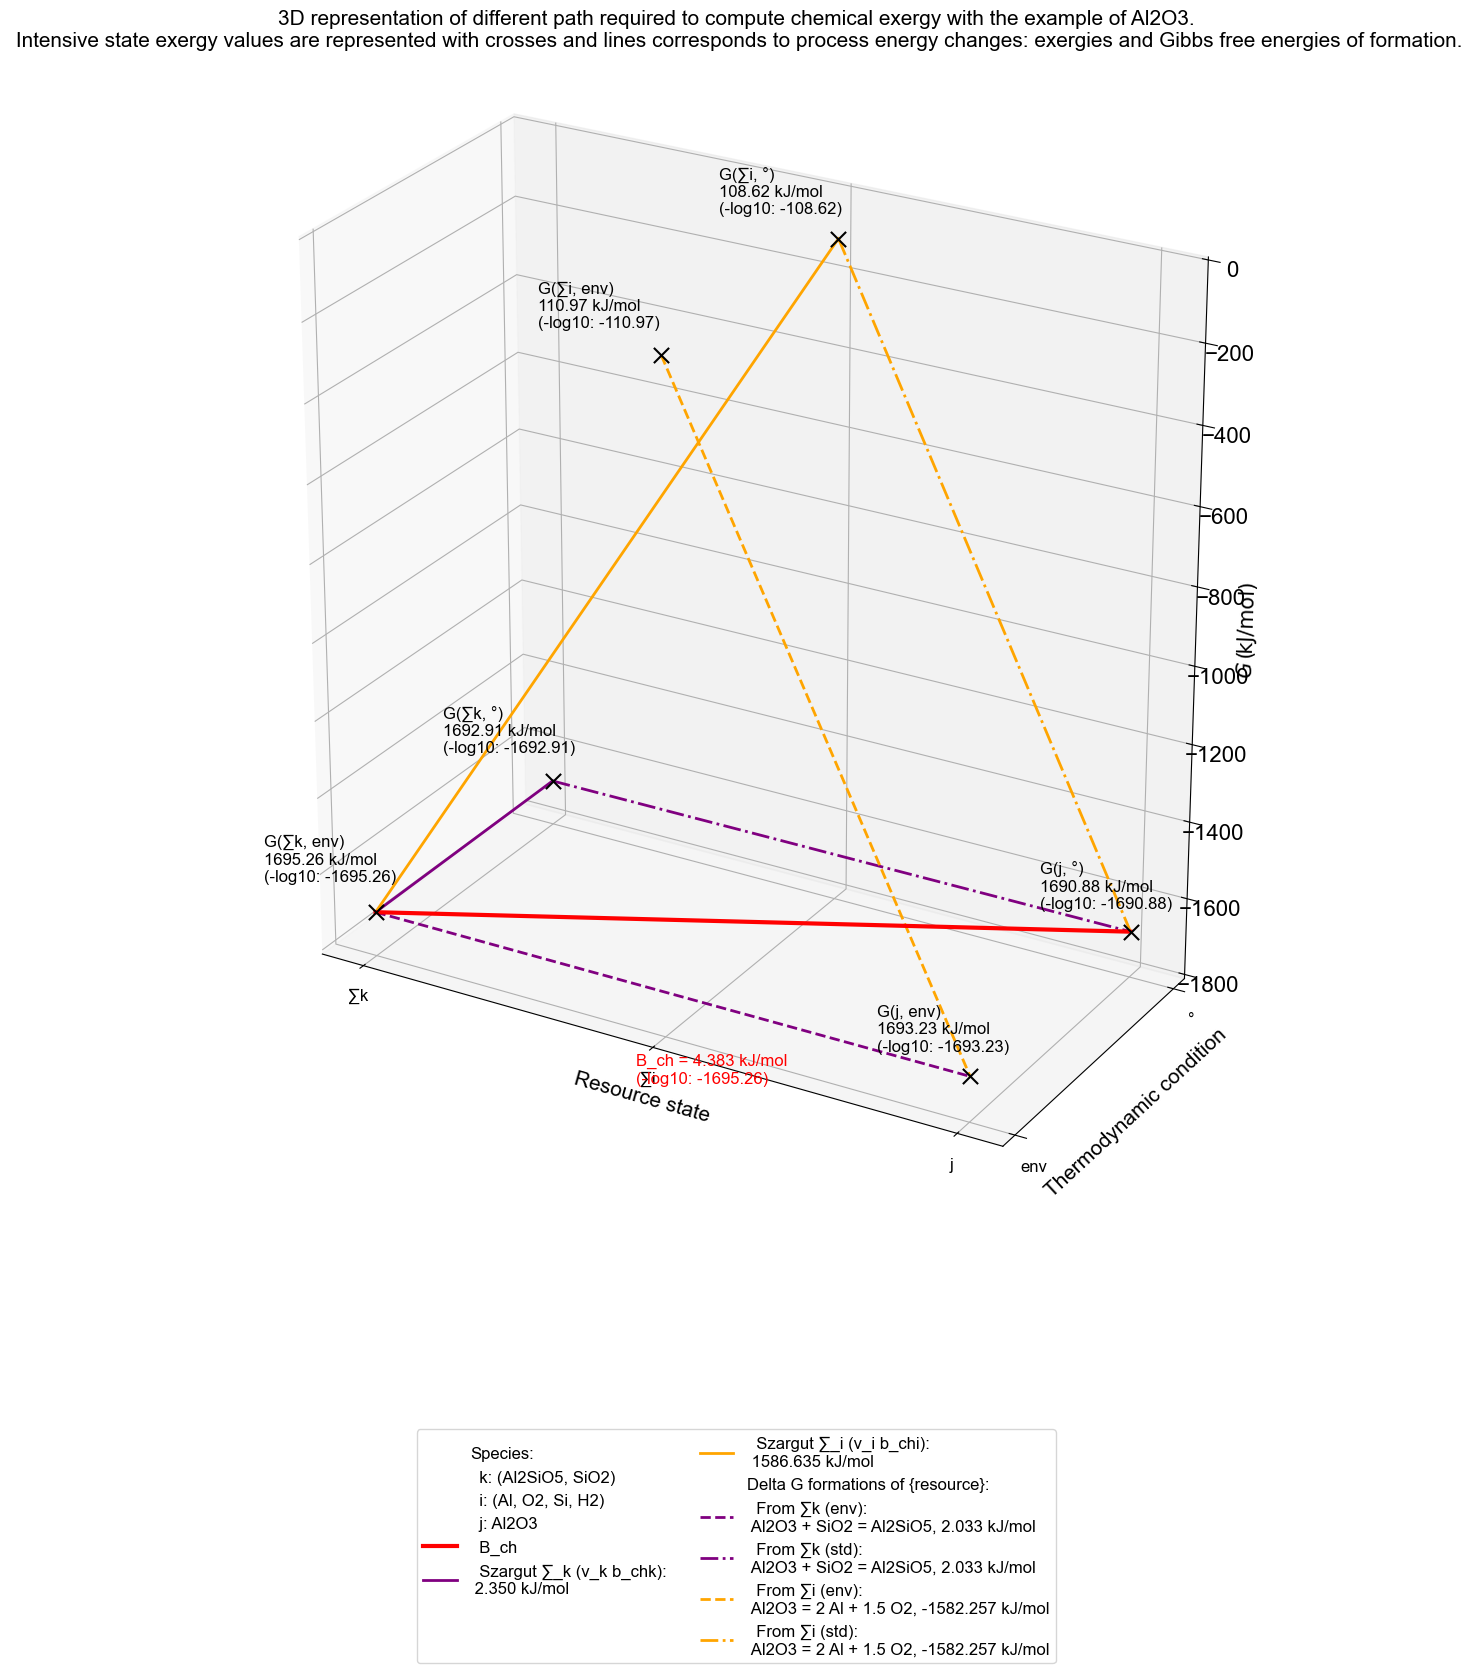

In [68]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

plt.rcParams['font.family'] = 'Arial'

fontsize_title = 15
fontsize_legend = 12

def plot_exergy_state_space_real(
    results,
    reference_elements_k,
    reference_elements_i,
    resource,
    filename='exergy_Al2O3_plot.svg',
    title=None
):
    """Plot the 3D exergy state-space for one computed results set."""
    if title is None:
        title = f'3D representation of different path required to compute chemical exergy with the example of {resource}.\n Intensive state exergy values are represented with crosses and lines corresponds to process energy changes: exergies and Gibbs free energies of formation.'

    G_env_sumk_in_j = results['G_env_sumk_in_j']
    G_env_j = results['G_env_j']
    G_std_sumk_in_j = results['G_std_sumk_in_j']
    G_std_j = results['G_std_j']
    G_env_sumi_in_j = results['G_env_sumi_in_j']
    G_std_sumi_in_j = results['G_std_sumi_in_j']

    x_positions = {
        '∑k': 0,
        '∑i': 1,
        'j': 2
    }

    y_positions = {
        'env': 0,
        '°': 1
    }

    color_map = {
        '∑k': 'purple',
        '∑i': 'orange',
        'j': 'black'
    }

    points = [
        ('∑k', 'env', G_env_sumk_in_j),
        ('j', 'env', G_env_j),
        ('∑k', '°', G_std_sumk_in_j),
        ('j', '°', G_std_j),
        ('∑i', 'env', G_env_sumi_in_j),
        ('∑i', '°', G_std_sumi_in_j),
    ]

    def z_transform(G):
        return (G)

    fig = plt.figure(figsize=(15, 15))
    ax = fig.add_subplot(111, projection='3d')

    for state, thermo, G in points:
        x = x_positions[state]
        y = y_positions[thermo]
        z = z_transform(G)

        ax.scatter(x, y, z, s=120, marker='x', color="black")

        dx = -0.4 if state in ['∑k', '∑i'] else -0.3
        dz = 0 if state in ['∑k', '∑i'] else -0.5
        ax.text(
            x + dx,
            y,
            z + dz,
            f"G({state}, {thermo})\n{abs(G):.2f} kJ/mol\n(-log10: {z:.2f})",  # Show both raw and transformed values
            fontsize=fontsize_legend,
            color="black"
        )       

    sum_k = '∑k'
    sum_i = '∑i'

    ax.plot(
        [x_positions['∑k'], x_positions['∑k']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_sumk_in_j)
        ],
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['∑i']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_sumi_in_j)
        ],
        linewidth=2,
        color='orange',
        label=None
    )

    delta_G_k = G_env_j - G_env_sumk_in_j
    delta_G_i = G_env_j - G_env_sumi_in_j

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['env'], y_positions['env']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_env_j)
        ],
        linestyle='--',
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['°'], y_positions['°']],
        [
            z_transform(G_std_sumk_in_j),
            z_transform(G_std_j)
        ],
        linestyle='-.',
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑i'], x_positions['j']],
        [y_positions['env'], y_positions['env']],
        [
            z_transform(G_env_sumi_in_j),
            z_transform(G_env_j)
        ],
        linestyle='--',
        linewidth=2,
        color='orange',
        label=None
    )

    ax.plot(
        [x_positions['∑i'], x_positions['j']],
        [y_positions['°'], y_positions['°']],
        [
            z_transform(G_std_sumi_in_j),
            z_transform(G_std_j)
        ],
        linestyle='-.',
        linewidth=2,
        color='orange',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_j)
        ],
        color='red',
        linewidth=3,
        label=None
    )

    B_ch = G_std_j - G_env_sumk_in_j
    b_chk = results.get('B_sumk_in_j', None)
    b_chi = results.get('B_sumi_in_j', None)

    bch_label_z = z_transform(G_env_sumk_in_j)  # Use transformed value
    ax.text(
        x_positions['∑i'] + 0.2,
        y_positions['°'] - 1.5,
        bch_label_z + 0.5,  # Adjust offset for transformed scale
        f"B_ch = {B_ch:.3f} kJ/mol\n(-log10: {bch_label_z:.2f})",
        color='red',
        fontsize=fontsize_legend
    )

    ax.set_xlabel('Resource state', fontsize=fontsize_title)
    ax.set_ylabel('Thermodynamic condition', fontsize=fontsize_title)
    ax.set_zlabel(r'$G\, (\mathrm{\!kJ/mol})$', fontsize=fontsize_title)

    ax.set_xticks(list(x_positions.values()))
    ax.set_xticklabels(list(x_positions.keys()), fontsize=fontsize_legend)
    ax.set_yticks(list(y_positions.values()))
    ax.set_yticklabels(list(y_positions.keys()), fontsize=fontsize_legend)
    ax.set_box_aspect((2, 1, 2))
    ax.view_init(elev=25, azim=-60)

    plt.title(title, fontsize=fontsize_title)

    import matplotlib.lines as mlines
    handles = []
    labels = []

    labels.append('Species:')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  k: ({", ".join(reference_elements_k)})')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  i: ({", ".join(reference_elements_i)})')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  j: {resource}')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append('  B_ch')
    handles.append(mlines.Line2D([0], [0], color='red', linewidth=3))

    labels.append(f'  Szargut ∑_k (ν_k b_chk):\n {b_chk:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linewidth=2))

    labels.append(f'  Szargut ∑_i (ν_i b_chi):\n {b_chi:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linewidth=2))

    labels.append('Delta G formations of {resource}:')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  From {sum_k} (env):\n Al2O3 + SiO2 = Al2SiO5, {delta_G_k:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linestyle='--', linewidth=2))

    labels.append(f'  From {sum_k} (std):\n Al2O3 + SiO2 = Al2SiO5, {delta_G_k:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linestyle='-.', linewidth=2))

    labels.append(f'  From {sum_i} (env):\n Al2O3 = 2 Al + 1.5 O2, {delta_G_i:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linestyle='--', linewidth=2))

    labels.append(f'  From {sum_i} (std):\n Al2O3 = 2 Al + 1.5 O2, {delta_G_i:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linestyle='-.', linewidth=2))

    ax.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.4), ncol=2, fontsize=fontsize_legend)
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()

plot_exergy_state_space_real(
    results_szargut,
    reference_elements_k=reference_environment_species_k_szargut,
    reference_elements_i=reference_elements_i,
    resource=resource,    
    filename='exergy_abs_Al2O3_plot.svg'
)

## all 6Gs, B_ch, DeltaG

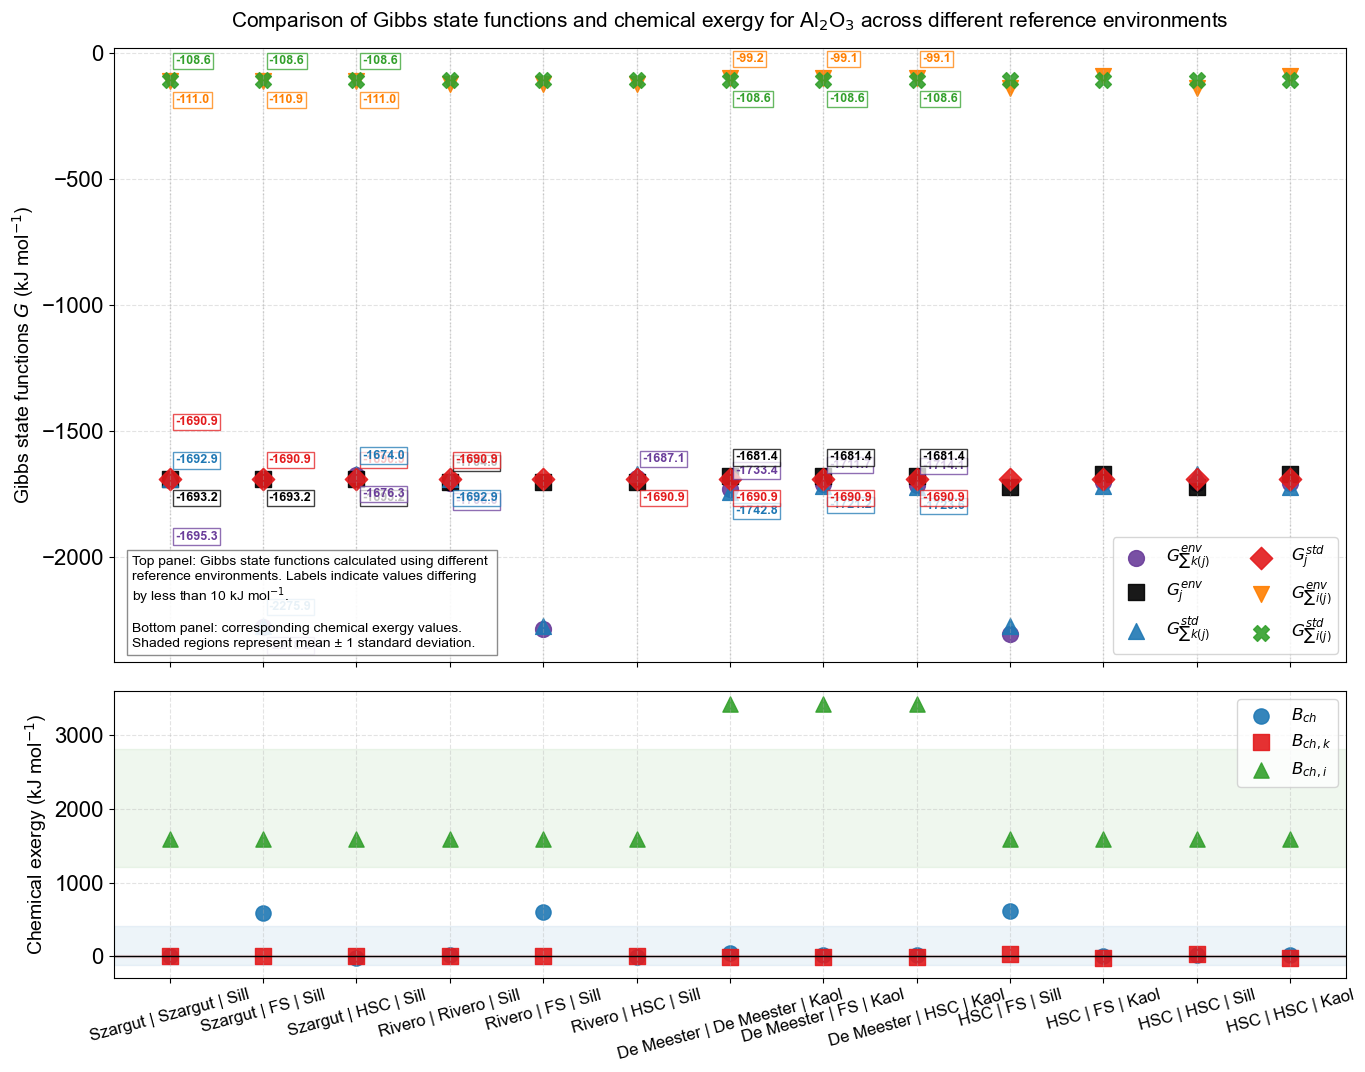

In [69]:
# ============================================================================
# ENHANCED PLOT WITH GIBBS FREE ENERGY VARIATIONS
# ============================================================================

# =============================================================================
# PLOT — G STATE FUNCTIONS + CHEMICAL EXERGY
# =============================================================================

def plot_exergy_comparison(
    df,
    filename='G_and_exergy_comparison.svg',
    similarity_threshold=10 # kJ/mol
):

    # -------------------------------------------------------------------------
    # FIGURE
    # -------------------------------------------------------------------------

    fig, (ax1, ax2) = plt.subplots(
        2,
        1,
        figsize=(14, 11),
        sharex=True,
        gridspec_kw={'height_ratios': [3, 1.4]}
    )

    methods = df['method'].tolist()
    x = np.arange(len(methods))

    # -------------------------------------------------------------------------
    # G STATE FUNCTIONS
    # -------------------------------------------------------------------------

    G_columns = [
        'G_env_sumk_in_j',
        'G_env_j',
        'G_std_sumk_in_j',
        'G_std_j',
        'G_env_sumi_in_j',
        'G_std_sumi_in_j'
    ]

    G_labels = [
        r'$G_{\sum k(j)}^{env}$',
        r'$G_{j}^{env}$',
        r'$G_{\sum k(j)}^{std}$',
        r'$G_{j}^{std}$',
        r'$G_{\sum i(j)}^{env}$',
        r'$G_{\sum i(j)}^{std}$'
    ]

    G_colors = [
        '#6a3d9a',
        '#000000',
        '#1f78b4',
        '#e31a1c',
        '#ff7f00',
        '#33a02c'
    ]

    G_markers = ['o', 's', '^', 'D', 'v', 'X']

    # -------------------------------------------------------------------------
    # STORE POINT DATA
    # -------------------------------------------------------------------------

    point_data = []

    # -------------------------------------------------------------------------
    # PLOT G VALUES
    # -------------------------------------------------------------------------

    for col, label, color, marker in zip(
        G_columns,
        G_labels,
        G_colors,
        G_markers
    ):

        y = df[col].values

        ax1.scatter(
            x,
            y,
            marker=marker,
            s=130,
            color=color,
            label=label,
            alpha=0.9
        )

        for xi, yi in zip(x, y):

            point_data.append({
                'x': xi,
                'y': yi,
                'color': color
            })

    # -------------------------------------------------------------------------
    # LABEL VERY SIMILAR VALUES
    # -------------------------------------------------------------------------

    # -------------------------------------------------------------------------
    # LABEL CLUSTERS OF VERY SIMILAR VALUES
    # -------------------------------------------------------------------------

    for xi in x:

        local_points = [
            p for p in point_data
            if p['x'] == xi
        ]

        # sort by y value
        local_points = sorted(local_points, key=lambda p: p['y'])

        clusters = []
        current_cluster = [local_points[0]]

        # build clusters of nearby points
        for p in local_points[1:]:

            if abs(p['y'] - current_cluster[-1]['y']) < similarity_threshold:

                current_cluster.append(p)

            else:

                clusters.append(current_cluster)
                current_cluster = [p]

        clusters.append(current_cluster)

        # ---------------------------------------------------------------------
        # LABEL CLUSTERS
        # ---------------------------------------------------------------------

        for cluster in clusters:

            # only annotate clusters with at least 2 nearby values
            if len(cluster) >= 2:

                for idx, p in enumerate(cluster):

                    # symmetric offsets around point
                    offset = (idx - (len(cluster)-1)/2) * 150

                    ax1.text(
                        p['x'] + 0.06,
                        p['y'] + offset,
                        f'{p["y"]:.1f}',
                        fontsize=9,
                        color=p['color'],
                        va='center',
                        fontweight='bold',
                        bbox=dict(
                            facecolor='white',
                            edgecolor=p['color'],
                            alpha=0.75,
                            pad=1.5
                        )
                    )
    # -------------------------------------------------------------------------
    # GUIDE LINES
    # -------------------------------------------------------------------------

    for xi in x:

        ax1.axvline(
            xi,
            color='lightgray',
            linestyle=':',
            linewidth=1,
            zorder=0
        )

    # -------------------------------------------------------------------------
    # TOP PANEL FORMAT
    # -------------------------------------------------------------------------

    ax1.set_ylabel(
        r'Gibbs state functions $G$ (kJ mol$^{-1}$)',
        fontsize=fontsize_label
    )

    ax1.set_title(
        r'Comparison of Gibbs state functions and chemical exergy '
        r'for Al$_2$O$_3$ across different reference environments',
        fontsize=fontsize_title,
        pad=15
    )

    ax1.grid(
        linestyle='--',
        alpha=0.35
    )

    ax1.legend(
        fontsize=fontsize_legend,
        ncol=2,
        frameon=True
    )

    # -------------------------------------------------------------------------
    # CHEMICAL EXERGY PANEL
    # -------------------------------------------------------------------------

    exergy_columns = [
        'B_ch',
        'B_chk',
        'B_chi'
    ]

    exergy_labels = [
        r'$B_{ch}$',
        r'$B_{ch,k}$',
        r'$B_{ch,i}$'
    ]

    exergy_colors = [
        '#1f78b4',
        '#e31a1c',
        '#33a02c'
    ]

    exergy_markers = ['o', 's', '^']

    for col, label, color, marker in zip(
        exergy_columns,
        exergy_labels,
        exergy_colors,
        exergy_markers
    ):

        ax2.scatter(
            x,
            df[col],
            marker=marker,
            s=120,
            color=color,
            label=label,
            alpha=0.9
        )

        # variability envelope
        mean = df[col].mean()
        std = df[col].std(ddof=1)

        ax2.axhspan(
            mean - std,
            mean + std,
            alpha=0.08,
            color=color
        )

    # -------------------------------------------------------------------------
    # BOTTOM PANEL FORMAT
    # -------------------------------------------------------------------------

    ax2.axhline(
        0,
        color='black',
        linewidth=1
    )

    ax2.grid(
        linestyle='--',
        alpha=0.35
    )

    ax2.set_ylabel(
        r'Chemical exergy (kJ mol$^{-1}$)',
        fontsize=fontsize_label
    )

    ax2.set_xticks(x)

    ax2.set_xticklabels(
        methods,
        rotation=15,
        fontsize=fontsize_ticks
    )

    ax2.legend(
        fontsize=fontsize_legend,
        loc='best'
    )

    # -------------------------------------------------------------------------
    # CAPTION
    # -------------------------------------------------------------------------

    txt = (
        r'Top panel: Gibbs state functions calculated using different '
        '\nreference environments. Labels indicate values differing '
        f'\nby less than {similarity_threshold} kJ mol$^{{-1}}$.'
        '\n'
        '\nBottom panel: corresponding chemical exergy values.'
        '\nShaded regions represent mean ± 1 standard deviation.'
    )

    ax1.text(
        0.015,
        0.02,
        txt,
        transform=ax1.transAxes,
        fontsize=10,
        verticalalignment='bottom',
        bbox=dict(
            facecolor='white',
            edgecolor='gray',
            alpha=0.9
        )
    )

    # -------------------------------------------------------------------------
    # LAYOUT
    # -------------------------------------------------------------------------

    plt.tight_layout()

    plt.savefig(
        filename,
        dpi=600,
        bbox_inches='tight'
    )

    plt.show()


# =============================================================================
# BUILD DATAFRAME
# =============================================================================

def build_exergy_dataframe(results_dict):
    """
    Convert all methods results into a dataframe.
    """

    rows = []

    for method_name, results in results_dict.items():

        B_ch = results['G_std_j'] - results['G_env_sumk_in_j']

        row = {
            'method': method_name,

            'G_env_sumk_in_j': results['G_env_sumk_in_j'],
            'G_env_j': results['G_env_j'],
            'G_std_sumk_in_j': results['G_std_sumk_in_j'],
            'G_std_j': results['G_std_j'],
            'G_env_sumi_in_j': results['G_env_sumi_in_j'],
            'G_std_sumi_in_j': results['G_std_sumi_in_j'],

            'B_ch': B_ch,
            'B_chk': results.get('B_sumk_in_j', np.nan),
            'B_chi': results.get('B_sumi_in_j', np.nan),
        }

        rows.append(row)

    df = pd.DataFrame(rows)

    return df

# Compute results for all configurations
results_all_complete = {}
for config in configurations:
    try:
        results = compute_all_G_values(
            DeltafrG_std=config["DeltafrG_std"],
            S_std=S_std_FS if "FactSage" in config["DeltafrG_source"] else (S_std_HSC if "HSC" in config["DeltafrG_source"] else S_std_brgm),
            H_std=H_std,
            G_std=G_std,
            resource=resource,
            reference_elements_i=reference_elements_i,
            reference_species_k=config["env_species_order"],
            reaction_formation_j_from_i=reaction_formation_jfromis_sc,
            reaction_formation_j_from_k=reaction_formation_jfromks_sc_szargut if "Sillimanite" in config["env_species_Al"] else reaction_formation_jfromks_sc_demeester,
            chem_exergy_k=config["chem_exergy_k"],
            chem_exergy_i=config["b_chk_init"],
            Tenv=Tenv,
            standard_state_equivalencies=standard_state_equivalencies
        )
        results_all_complete[config["short_label"]] = results
    except Exception as e:
        print(f"Error computing results for {config['name']}: {e}")
        results_all_complete[config["short_label"]] = None


# Build dataframe and plot
df_exergy_complete = build_exergy_dataframe(results_all_complete)
plot_exergy_comparison(
    df_exergy_complete,
    filename='G_and_exergy_comparison_complete.svg'
)

## DeltaG discrepencies


TABLE: Standard Gibbs Free Energy Variations (ΔG°) for All Configurations
                 Configuration  ΔG°(j ← k)  ΔG°(j ← i)  ΔG°(k ← i)
      Szargut | Szargut | Sill      2.0330  -1582.2570  -1584.2900
           Szargut | FS | Sill    585.0260  -1582.2937  -2167.3197
          Szargut | HSC | Sill    -16.9120  -1582.2740  -1565.3620
        Rivero | Rivero | Sill      2.0330  -1582.2570  -1584.2900
            Rivero | FS | Sill    585.0260  -1582.2937  -2167.3197
           Rivero | HSC | Sill    -16.9120  -1582.2740  -1565.3620
De Meester | De Meester | Kaol     51.9480  -1582.2570  -1634.2050
        De Meester | FS | Kaol     30.3459  -1582.2937  -1612.6396
       De Meester | HSC | Kaol     32.6870  -1582.2740  -1614.9610
               HSC | FS | Sill    585.0260  -1582.2937  -2167.3197
               HSC | FS | Kaol     30.3459  -1582.2937  -1612.6396
              HSC | HSC | Sill    -16.9120  -1582.2740  -1565.3620
              HSC | HSC | Kaol     32.6870  -1582.2740

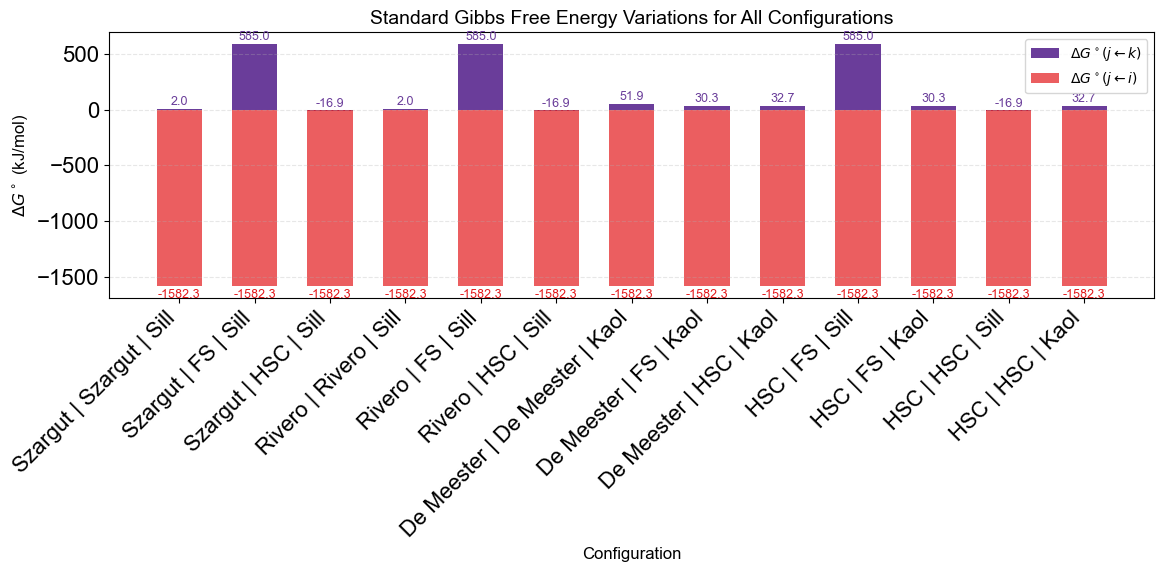

In [70]:
# ============================================================================
# COMPUTE AND DISPLAY ΔG VALUES IN STANDARD STATE
# ============================================================================

# Create a dictionary to store ΔG values for each configuration
delta_G_results = []

for config in configurations:
    try:
        # Compute the results for this configuration
        results = compute_all_G_values(
            DeltafrG_std=config["DeltafrG_std"],
            S_std=S_std_FS if "FactSage" in config["DeltafrG_source"] else (S_std_HSC if "HSC" in config["DeltafrG_source"] else S_std_brgm),
            H_std=H_std,
            G_std=G_std,
            resource=resource,
            reference_elements_i=reference_elements_i,
            reference_species_k=config["env_species_order"],
            reaction_formation_j_from_i=reaction_formation_jfromis_sc,
            reaction_formation_j_from_k=reaction_formation_jfromks_sc_szargut if "Sillimanite" in config["env_species_Al"] else reaction_formation_jfromks_sc_demeester,
            chem_exergy_k=config["chem_exergy_k"],
            chem_exergy_i=config["b_chk_init"],
            Tenv=Tenv,
            standard_state_equivalencies=standard_state_equivalencies
        )

        # Extract the ΔG values in standard state
        delta_G_std_jk = results["DeltaG_std_jk"]  # ΔG°(j ← k)
        delta_G_std_ji = results["DeltaG_std_ji"]  # ΔG°(j ← i)

        # Add to results
        delta_G_results.append({
            "Configuration": config["short_label"],
            "ΔG°(j ← k)": delta_G_std_jk,
            "ΔG°(j ← i)": delta_G_std_ji,
            "ΔG°(k ← i)": results["G_std_sumk_in_j"] - results["G_std_sumi_in_j"]
        })

    except Exception as e:
        print(f"Error computing ΔG for {config['name']}: {e}")
        delta_G_results.append({
            "Configuration": config["short_label"],
            "ΔG°(j ← k)": None,
            "ΔG°(j ← i)": None,
            "ΔG°(k ← i)": None
        })

# Create a DataFrame for the ΔG values
df_delta_G = pd.DataFrame(delta_G_results)

# Display the ΔG values table
print("\n" + "="*100)
print("TABLE: Standard Gibbs Free Energy Variations (ΔG°) for All Configurations")
print("="*100)
print(df_delta_G.to_string(index=False))
print("="*100)

# Plot the ΔG values
plt.figure(figsize=(12, 6))

# Plot ΔG°(j ← k)
bars1 = plt.bar(
    df_delta_G["Configuration"],
    df_delta_G["ΔG°(j ← k)"],
    width=0.6,
    color='#6a3d9a',
    label=r'$\Delta G^\circ(j \leftarrow k)$'
)

# Plot ΔG°(j ← i)
bars2 = plt.bar(
    df_delta_G["Configuration"],
    df_delta_G["ΔG°(j ← i)"],
    width=0.6,
    color='#e31a1c',
    alpha=0.7,
    label=r'$\Delta G^\circ(j \leftarrow i)$'
)

# Add value labels
for bar1, bar2, (jk, ji) in zip(bars1, bars2, zip(df_delta_G["ΔG°(j ← k)"], df_delta_G["ΔG°(j ← i)"])):
    plt.text(bar1.get_x() + bar1.get_width()/2, jk + 10,
             f'{jk:.1f}', ha='center', va='bottom', fontsize=9, color='#6a3d9a')
    plt.text(bar2.get_x() + bar2.get_width()/2, ji - 30,
             f'{ji:.1f}', ha='center', va='top', fontsize=9, color='#e31a1c')

plt.xlabel("Configuration", fontsize=12)
plt.ylabel(r"$\Delta G^\circ$ (kJ/mol)", fontsize=12)
plt.title("Standard Gibbs Free Energy Variations for All Configurations", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.legend(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
# plt.savefig('delta_G_standard_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# end and test

In [71]:
import pandas as pd

def compute_B_consistency_table(results_all: dict) -> pd.DataFrame:
    rows = []

    for method, res in results_all.items():

        # --- Form 1: elements route ---
        B_j_1 = res["B_sumi_in_j"] + res["DeltaG_std_ji"]

        # --- Form 2: environmental route ---
        B_j_2 = res["B_sumk_in_j"] + res["DeltaG_std_jk"]

        # --- Form 3: state function route ---
        B_j_3 = res["G_std_j"] - res["G_env_sumk_in_j"]

        # --- Difference ---
        diff = B_j_1 - B_j_2

        rows.append({
            "method": method,
            "B_j_1 (i-route)": B_j_1,
            "B_j_2 (k-route)": B_j_2,
            "B_j_3 (state function route)": B_j_3,
            "difference ik routes": diff,
            "abs_difference ik routes": abs(diff)
        })

    return pd.DataFrame(rows)

In [72]:
df_B_check = compute_B_consistency_table(results_all_complete)
df_B_check

,method,B_j_1 (i-route),B_j_2 (k-route),B_j_3 (state function route),difference ik routes,abs_difference ik routes
0,Szargut | Szargut | Sill,4.3780,4.3830,4.3830,-0.0050,0.0050
1,Szargut | FS | Sill,4.3413,587.3760,587.3760,-583.0347,583.0347
2,Szargut | HSC | Sill,4.3610,-14.5620,-14.5620,18.9230,18.9230
3,Rivero | Rivero | Sill,15.0230,15.1230,15.1230,-0.1000,0.1000
4,Rivero | FS | Sill,14.9863,598.1160,598.1160,-583.1297,583.1297
5,Rivero | HSC | Sill,15.0060,-3.8220,-3.8220,18.8280,18.8280
6,De Meester | De Meester | Kaol,1842.2930,42.4880,42.4880,1799.8050,1799.8050
7,De Meester | FS | Kaol,1842.2563,20.8859,20.8859,1821.3704,1821.3704
8,De Meester | HSC | Kaol,1842.2760,23.2270,23.2270,1819.0490,1819.0490
9,HSC | FS | Sill,14.9863,616.9460,616.9460,-601.9597,601.9597


In [73]:
# Temporary diagnostics cell: per-element sample sizes and factor-level counts
print('Per-element diagnostics:')
for el in sorted(df_long['element'].dropna().unique()):
    dfe = df_long[df_long['element']==el].dropna(subset=['b_ch']).copy()
    n = dfe.shape[0]
    if n>0:
        y = dfe['b_ch'].values
        total_ss = float(np.sum((y - np.mean(y))**2))
    else:
        total_ss = float('nan')
    print(f'{el}: n={n}, total_ss={total_ss:.6g}')
    print('  b_ch_species sources:', list(dfe['b_ch_source'].unique()))
    print('  dG_source levels:', list(dfe['dG_source'].unique()))
    print('  ref_env species:', list(dfe['ref_env'].unique()))
    print('  group counts:')
    print(dfe.groupby(['b_ch_source','dG_source','ref_env']).size().to_string())
    print('-'*60)

Per-element diagnostics:
Al: n=13, total_ss=199988
  b_ch_species sources: ['Szargut', 'Rivero', 'De Meester', 'HSC']
  dG_source levels: ['Szargut', 'FactSage', 'HSC', 'Rivero', 'De Meester']
  ref_env species: ['Sillimanite', 'Kaolinite']
  group counts:
b_ch_source  dG_source   ref_env    
De Meester   De Meester  Kaolinite      1
             FactSage    Kaolinite      1
             HSC         Kaolinite      1
HSC          FactSage    Kaolinite      1
                         Sillimanite    1
             HSC         Kaolinite      1
                         Sillimanite    1
Rivero       FactSage    Sillimanite    1
             HSC         Sillimanite    1
             Rivero      Sillimanite    1
Szargut      FactSage    Sillimanite    1
             HSC         Sillimanite    1
             Szargut     Sillimanite    1
------------------------------------------------------------
H2: n=13, total_ss=236.989
  b_ch_species sources: ['Szargut', 'Rivero', 'De Meester', 'HSC']
  dG_